# Feature analysis and leakage-safe preprocessing

In [1]:
from pathlib import Path
import re, json, hashlib, zipfile, io
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Image, Markdown
from bs4 import BeautifulSoup
from scipy import stats

REPO_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
                 if (path / "dataset").is_dir() and (path / "notebooks").is_dir())
OUTPUT_ROOT = REPO_ROOT / "artifacts"  # generated tables, models, predictions and figures
(OUTPUT_ROOT / "Configs").mkdir(parents=True, exist_ok=True)
SHARED_DATASET_ROOT = REPO_ROOT / "dataset"
for folder in ["Processed", "Interim", "Features", "Splits"]:
    (SHARED_DATASET_ROOT / folder).mkdir(parents=True, exist_ok=True)
RUN_ID = "racf_20261011"
TABLES = OUTPUT_ROOT / "Tables" / RUN_ID
PNG = OUTPUT_ROOT / "Figures/PNG/publication_20261012"
PDF = OUTPUT_ROOT / "Figures/PDF/publication_20261012"
for folder in [TABLES, PNG, PDF, SHARED_DATASET_ROOT / "Interim", SHARED_DATASET_ROOT / "Processed"]:
    folder.mkdir(parents=True, exist_ok=True)
np.random.seed(42)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.precision", 4)
font_manager.findfont("Times New Roman", fallback_to_default=False)
mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
    "axes.titlesize": 20, "axes.labelsize": 19, "xtick.labelsize": 18,
    "ytick.labelsize": 18, "legend.fontsize": 18, "figure.titlesize": 20,
    "figure.dpi": 350, "savefig.dpi": 350, "axes.unicode_minus": True,
    "pdf.fonttype": 42, "ps.fonttype": 42, "mathtext.fontset": "custom", "mathtext.rm": "Times New Roman", "mathtext.it": "Times New Roman:italic", "mathtext.bf": "Times New Roman:bold"})
plt.ioff();

import yaml, joblib
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mutual_info_score
from sklearn.linear_model import Ridge

protocol = yaml.safe_load((OUTPUT_ROOT / "Configs/experiment.yaml").read_text())
assert protocol["run_id"] == RUN_ID and not protocol["test_opened_for_model_selection"]
FEATURES_ROOT = SHARED_DATASET_ROOT / "Features"
SPLITS_ROOT = SHARED_DATASET_ROOT / "Splits"
FEATURES_ROOT.mkdir(exist_ok=True)
SPLITS_ROOT.mkdir(exist_ok=True)


In [2]:
MATRIX_PALETTES = {
    "spearman":"RdBu_r", "target_mi":"Purples", "pairwise_mi":"YlGnBu",
    "nonlinear":"YlGn", "interactions":"YlOrRd", "shift":"Blues",
}
assert len(set(MATRIX_PALETTES.values())) == len(MATRIX_PALETTES)


def scientific_table(frame: pd.DataFrame, name: str, caption: str) -> None:
    """Display every selected row and column and retain numerical source values."""
    assert not frame.isna().any().any(), f"{name}: explain undefined values before display"
    frame.to_csv(TABLES / f"{name}.csv", index=False)
    display(Markdown(f"**{caption}**"))
    display(frame.style.format(scientific_number).hide(axis="index"))


def publication_figure(fig, name: str, numerical_source: pd.DataFrame, caption: str) -> None:
    """Save the same 350-DPI canvas once and verify the actual visible fonts."""
    for item in fig.findobj(mpl.text.Text):
        item.set_text(re.sub(r"(?<![A-Za-z0-9])-(?=\d)|(?<=[eE])-(?=\d)", "−", item.get_text()))
    fig.canvas.draw()
    for item in fig.findobj(mpl.text.Text):
        if item.get_visible():
            assert not re.search(r"(?<![A-Za-z0-9])-(?=\d)|(?<=[eE])-(?=\d)", item.get_text()), item.get_text()
    for text in fig.findobj(mpl.text.Text):
        if text.get_visible() and text.get_text().strip():
            assert 18 <= text.get_fontsize() <= 20, text.get_text()
            font_path = font_manager.findfont(text.get_fontproperties(), fallback_to_default=False)
            assert "Times New Roman" in font_manager.FontProperties(fname=font_path).get_name()
    fig.savefig(PNG / f"{name}.png", dpi=350, bbox_inches="tight", pad_inches=0.12)
    fig.savefig(PDF / f"{name}.pdf", dpi=350, bbox_inches="tight", pad_inches=0.12)
    numerical_source.to_csv(TABLES / f"{name}_source.csv", index=False)
    plt.close(fig)
    display(Image(filename=str(PNG / f"{name}.png"), width=1000))
    display(Markdown(caption))


def normalize_name(value: str) -> str:
    return re.sub(r"[^a-z0-9]", "", str(value).lower())


def normalize_docket(value) -> str:
    digits = re.sub(r"\D", "", str(value)).lstrip("0")
    assert digits[:2] in {"50", "52"}, value
    return f"0{digits[:2]}{int(digits[2:]):05d}"


def scientific_number(value, decimals=4):
    """Typography only: preserve raw numeric values and Python arithmetic."""
    if pd.isna(value):
        raise ValueError("An undefined statistic requires an explicit scientific explanation")
    if isinstance(value, (int, np.integer)) and not isinstance(value, (bool, np.bool_)):
        return str(value).replace("-", "−")
    if isinstance(value, (float, np.floating)):
        if value == 0:
            return f"{0:.{decimals}f}"
        if abs(value) < 10**(-decimals):
            return f"{value:.2e}".replace("-", "−")
        return f"{value:.{decimals}f}".replace("-", "−")
    return re.sub(r"(?<![A-Za-z0-9])-(?=\d)|(?<=[eE])-(?=\d)", "−", str(value))


def matrix_canvas(matrix, labels, colorbar_label, *, cmap="viridis", vmin=0, vmax=1, decimals=2):
    """One annotated matrix; no accompanying table repeats its displayed values."""
    assert np.isfinite(matrix.to_numpy()).all(), "Explain undefined matrix statistics before rendering"
    fig, ax = plt.subplots(figsize=(1.6+0.67*len(labels),1.6+0.62*len(labels)))
    palette = mpl.colormaps[cmap].copy()
    palette.set_bad("#eeeeee")
    image = ax.imshow(matrix, vmin=vmin, vmax=vmax, cmap=palette)
    ax.set_xticks(range(len(labels)),labels,rotation=50,ha="right")
    ax.set_yticks(range(len(labels)),labels)
    for row in range(len(labels)):
        for column in range(len(labels)):
            value = matrix.iloc[row,column]
            label = matrix_number(value,decimals)
            rgba = image.cmap(image.norm(value)) if pd.notna(value) else (1,1,1,1)
            luminance = .2126*rgba[0]+.7152*rgba[1]+.0722*rgba[2]
            ax.text(column,row,label,ha="center",va="center",fontsize=18,color="black" if luminance>.5 else "white")
    fig.colorbar(image,ax=ax,fraction=.046,pad=.04,label=colorbar_label)
    return fig

def matrix_number(value, decimals=2):
    """Compact matrix labels: exact zero, rounded values, and a bound for small positive values."""
    if pd.isna(value):
        raise ValueError("An undefined matrix cell requires its sample count and reason")
    if 0 < value < 10**(-decimals):
        return "<" + f"{10**(-decimals):.{decimals}f}".lstrip("0")
    if abs(value) < .5*10**(-decimals):
        value = 0.0
    return f"{value:.{decimals}f}".replace("-", "−")


def annotation_color(image, value):
    """Choose readable text from the actual mapped cell color."""
    rgba = image.cmap(image.norm(value))
    luminance = .2126*rgba[0]+.7152*rgba[1]+.0722*rgba[2]
    return "black" if luminance>.5 else "white"


## Temporally admissible features

In [3]:
observations = pd.concat([pd.read_parquet(SHARED_DATASET_ROOT / f"Interim/{split}_observations.parquet") for split in ["train", "development", "calibration", "locked_test"]], ignore_index=True).sort_values(["reactor_id", "date"]).reset_index(drop=True)
assert not observations.observation_id.duplicated().any()
observations["segment_index"] = observations.groupby("reactor_id").date.transform(lambda s:s.diff().dt.days.ne(1).cumsum())
eia = pd.read_parquet(SHARED_DATASET_ROOT / "Processed/eia_nuclear_site_year.parquet").rename(columns={"source_year":"eia_source_year"})
observations["eia_source_year"] = observations.date.dt.year - protocol["eia_lag_years"]
observations = observations.merge(eia, on=["eia_plant_code", "eia_source_year"], how="left", validate="many_to_one")
features = pd.DataFrame(index=observations.index)
features["power_pct"] = observations.power_pct
features["delta_1d"] = observations.power_change
power_group = observations.groupby(["reactor_id", "segment_index"], sort=False).power_pct
for lag in [2, 3, 7, 14]:
    features[f"delta_{lag}d"] = observations.power_pct - power_group.shift(lag)
for window in [7, 14, 30]:
    for name, method in [("mean", "mean"), ("std", "std"), ("min", "min"), ("max", "max")]:
        features[f"power_{name}_{window}d"] = power_group.transform(lambda s:getattr(s.rolling(window, min_periods=window), method)())
    features[f"power_range_{window}d"] = features[f"power_max_{window}d"] - features[f"power_min_{window}d"]
features["zero_run_days"] = observations.groupby(["reactor_id", "segment_index"], sort=False).power_pct.transform(lambda s:s.eq(0).groupby(s.ne(0).cumsum()).cumsum()).astype(float)
features["days_since_change"] = observations.groupby(["reactor_id", "segment_index"], sort=False).power_pct.transform(lambda s:s.groupby(s.diff().abs().gt(2).cumsum()).cumcount()).astype(float)
features["power_window_fraction"] = power_group.transform(lambda s:s.rolling(30, min_periods=1).count())/30


In [4]:
weather_names = ["temp_c", "dewpoint_c", "pressure_hpa", "wind_ms", "precip_mm"]
for name in weather_names:
    features[name] = observations[name]
    features[f"{name}_missing"] = observations[name].isna().astype(float)
    features[f"{name}_mean7d"] = observations.groupby(["reactor_id", "segment_index"], sort=False)[name].transform(lambda s:s.rolling(7, min_periods=4).mean())
    last_valid = observations.date.where(observations[name].notna()).groupby(observations.reactor_id).ffill()
    features[f"{name}_age_days"] = (observations.date-last_valid).dt.days.add(3).clip(upper=365).fillna(365)
features["weather_missing_fraction"] = observations[weather_names].isna().mean(axis=1)
features["station_distance_km"] = observations.distance_km
features["reactor_is_pwr"] = observations.reactor_type.eq("PWR").astype(float)
features["site_nameplate_mw"] = observations.site_nameplate_mw
features["site_nuclear_generators"] = observations.nuclear_generators
features["site_generation_age_years"] = observations.date.dt.year - observations.first_generator_year
features["plant_lat"] = observations.plant_lat
features["plant_lon"] = observations.plant_lon
features["dayofyear_sin"] = np.sin(2*np.pi*(observations.date.dt.dayofyear-1)/365.2425)
features["dayofyear_cos"] = np.cos(2*np.pi*(observations.date.dt.dayofyear-1)/365.2425)
assert not np.isinf(features.to_numpy()).any()
assert all(features.dtypes.apply(pd.api.types.is_numeric_dtype))
forbidden_names = {"target", "event_id", "event_episode_id", "scram_type", "confirmed_scram", "label_source", "control_kind", "non_scram_event_id", "episode_id", "eligible"}
assert forbidden_names.isdisjoint(features.columns)
feature_groups = {"Power level and temporal dynamics":[c for c in features if c.startswith(("power", "delta", "zero", "days_since"))],
    "Weather and observation quality":[c for c in features if any(c.startswith(w) for w in weather_names) or c in ["weather_missing_fraction", "station_distance_km"]],
    "Physical and calendar context":[c for c in features if c.startswith(("site_", "plant_", "reactor_", "dayofyear_"))]}
assert set(sum(feature_groups.values(), [])) == set(features.columns)
feature_inventory = pd.DataFrame([{"Group":group, "Features":len(columns), "Information boundary":"Through t" if group.startswith("Power") else ("Weather ≤ t−3; no future imputation" if group.startswith("Weather") else "Physical properties; EIA year≤year(t)−2")} for group, columns in feature_groups.items()])
scientific_table(feature_inventory, "nb02_feature_groups", "Predictors and availability boundaries; label identifiers are excluded")
train_mask = observations.split.eq("train") & observations.eligible
analysis = pd.concat([observations[["observation_id", "reactor_id", "plant_id", "date", "target", "eligible", "control_kind"]], features], axis=1).loc[train_mask].copy()


**Predictors and availability boundaries; label identifiers are excluded**

Group,Features,Information boundary
Power level and temporal dynamics,24,Through t
Weather and observation quality,22,Weather ≤ t−3; no future imputation
Physical and calendar context,8,Physical properties; EIA year≤year(t)−2


## Lags, weather and seasonal adjustment

In [5]:
site_days = observations.loc[observations.split.eq("train") & ~observations.after_recorded_shutdown].groupby(["plant_id", "date"]).agg(power_pct=("power_pct", "mean"), **{w:(w, "mean") for w in weather_names}).reset_index()
site_days["month"] = site_days.date.dt.month
adjusted = site_days[["power_pct", *weather_names]] - site_days.groupby(["plant_id", "month"])[["power_pct", *weather_names]].transform("mean")
correlation_records = []
for weather in weather_names:
    raw_pair = site_days[["power_pct", weather]].dropna()
    adjusted_pair = adjusted[["power_pct", weather]].dropna()
    for method in ["pearson", "spearman"]:
        correlation_records.append({"Weather":weather, "Method":method, "n_site_days":len(raw_pair), "Raw":raw_pair.corr(method=method).iloc[0,1], "Site_month_adjusted":adjusted_pair.corr(method=method).iloc[0,1]})
correlations = pd.DataFrame(correlation_records)
scientific_table(correlations.loc[correlations.Method.eq("pearson")].drop(columns="Method"), "nb02_weather_pearson", "Pearson associations between power level and available weather; training data only")
scientific_table(correlations.loc[correlations.Method.eq("spearman")].drop(columns="Method"), "nb02_weather_spearman", "Spearman rank associations; agreement with Pearson does not establish causality")


**Pearson associations between power level and available weather; training data only**

Weather,n_site_days,Raw,Site_month_adjusted
temp_c,78428,−0.0062,0.0012
dewpoint_c,73618,0.0122,0.0088
pressure_hpa,56014,0.0114,0.0051
wind_ms,78362,−0.0244,−0.0007
precip_mm,52848,−0.0034,0.0015


**Spearman rank associations; agreement with Pearson does not establish causality**

Weather,n_site_days,Raw,Site_month_adjusted
temp_c,78428,0.0397,0.0036
dewpoint_c,73618,0.0587,0.0124
pressure_hpa,56014,−0.0135,0.0058
wind_ms,78362,−0.0173,−0.0007
precip_mm,52848,0.0106,−0.0103


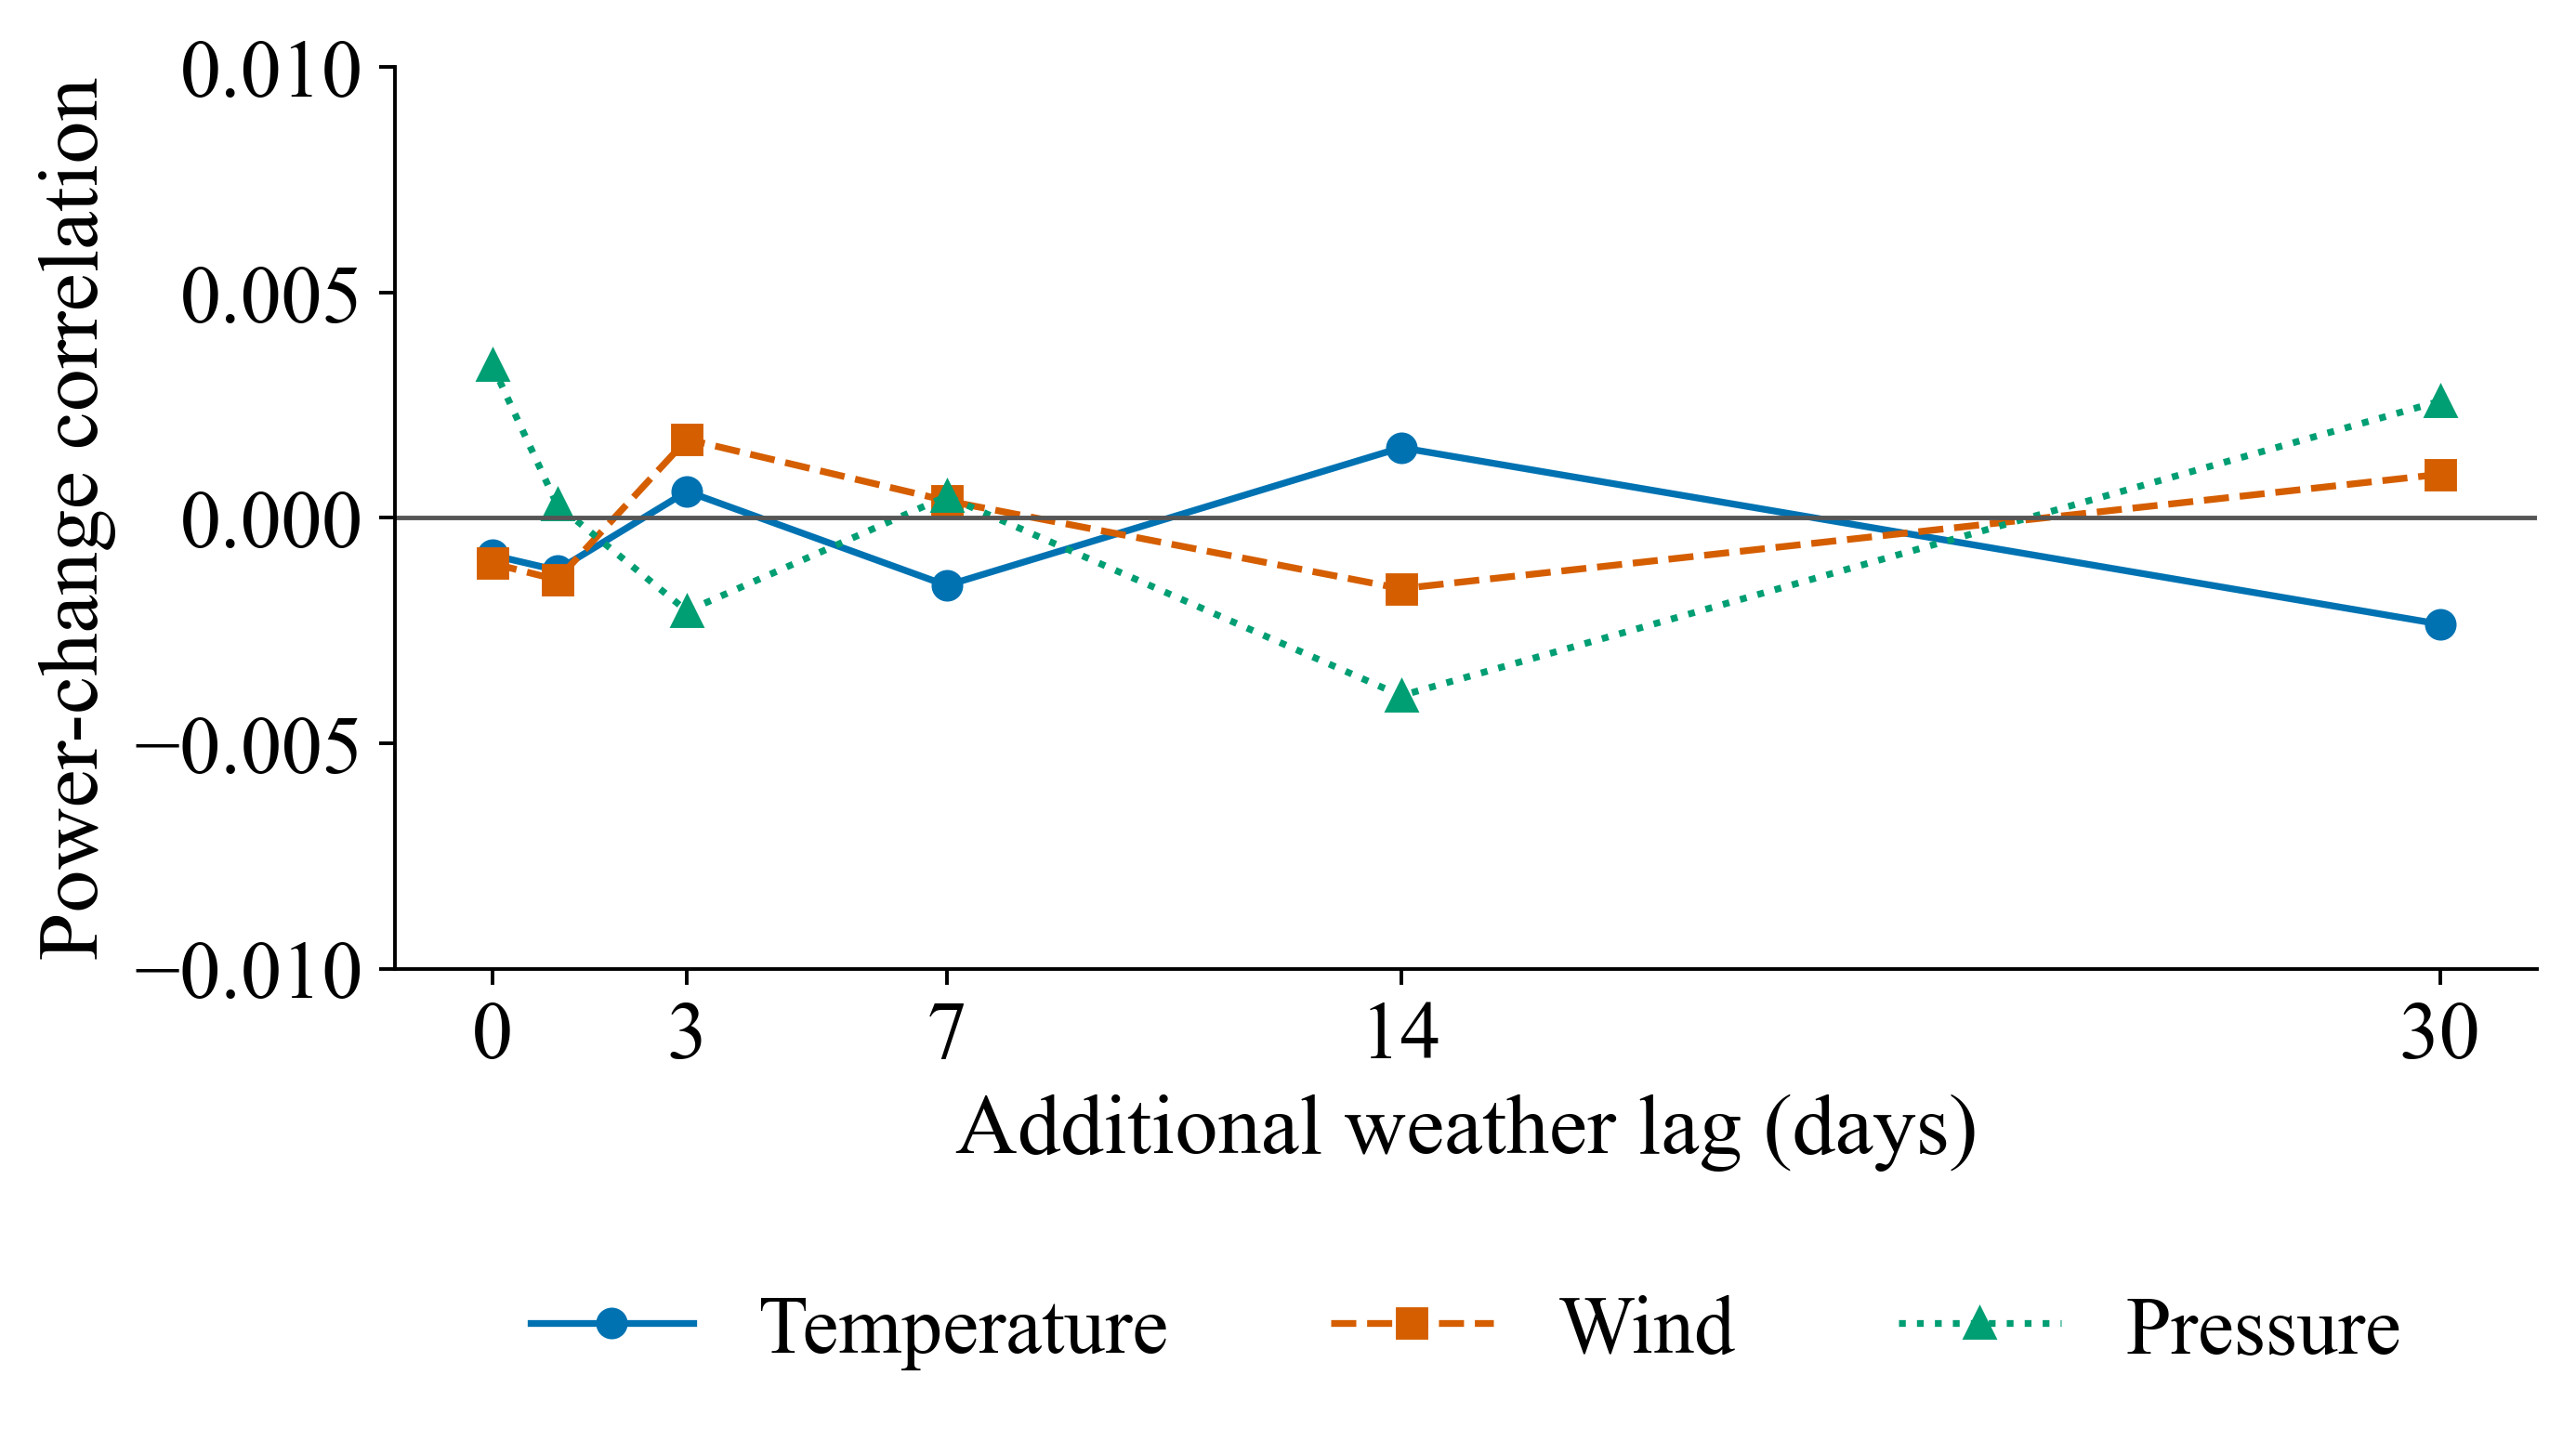

Associations between power change and weather at additional lags of 0–30 days after the initial three-day lag. All weather values precede the power report. The ±0.01 scale shows small effects; all absolute correlations are below 0.004. Associations are descriptive, not causal.

In [6]:
lag_records = []
for weather in ["temp_c", "wind_ms", "pressure_hpa"]:
    for lag in [0, 1, 3, 7, 14, 30]:
        future_safe_weather = site_days.groupby("plant_id")[weather].shift(lag)
        paired = pd.DataFrame({"power_change":site_days.groupby("plant_id").power_pct.diff(), "weather":future_safe_weather}).dropna()
        lag_records.append({"Weather":weather, "Additional lag (days)":lag, "r":paired.corr().iloc[0,1], "n":len(paired)})
lag_results = pd.DataFrame(lag_records)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for weather, label, color, style, marker in [("temp_c", "Temperature", "#0072B2", "-", "o"), ("wind_ms", "Wind", "#D55E00", "--", "s"), ("pressure_hpa", "Pressure", "#009E73", ":", "^")]:
    part = lag_results.loc[lag_results.Weather.eq(weather)]
    ax.plot(part["Additional lag (days)"], part.r, color=color, ls=style, marker=marker, label=label)
ax.axhline(0, color="#555555", lw=1)
ax.set(xlabel="Additional weather lag (days)", ylabel="Power-change correlation", xticks=[0, 3, 7, 14, 30], ylim=(-.01, .01))
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.28), ncol=3, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
publication_figure(fig, "nb02_weather_lags", lag_results, "Associations between power change and weather at additional lags of 0–30 days after the initial three-day lag. All weather values precede the power report. The ±0.01 scale shows small effects; all absolute correlations are below 0.004. Associations are descriptive, not causal.")


## Nonlinear relationships and control definitions

In [7]:
temperature_view = analysis.loc[analysis.temp_c.notna()].copy()
temperature_view["Temperature interval"] = pd.cut(temperature_view.temp_c, bins=[-60, -10, 0, 10, 20, 30, 60], right=False)
temperature_summary = temperature_view.groupby("Temperature interval", observed=True).agg(n=("target", "size"), confirmed_scram=("target", "sum"), mean_power=("power_pct", "mean"), mean_absolute_change=("delta_1d", lambda s:s.abs().mean())).reset_index()
temperature_summary["Events per 1000 selected days"] = 1000*temperature_summary.confirmed_scram/temperature_summary.n
temperature_summary["Temperature interval"] = temperature_summary["Temperature interval"].astype(str)
scientific_table(temperature_summary, "nb02_temperature_strata", "Temperature strata in the training cohort; frequencies are not population risks")
control_dynamics = analysis.groupby("control_kind").agg(n=("target", "size"), median_power=("power_pct", "median"), median_change=("delta_1d", "median"), q10_change=("delta_1d", lambda s:s.quantile(.1)), q90_change=("delta_1d", lambda s:s.quantile(.9)), median_range7d=("power_range_7d", "median")).reset_index()
scientific_table(control_dynamics, "nb02_control_dynamics", "Dynamics of confirmed events, documented controls and stable regimes")


**Temperature strata in the training cohort; frequencies are not population risks**

Temperature interval,n,confirmed_scram,mean_power,mean_absolute_change,Events per 1000 selected days
"[−60, −10)",1396,0,98.1712,0.0265,0.0000
"[−10, 0)",8766,3,97.6087,0.0746,0.3422
"[0, 10)",27473,42,93.3522,0.1220,1.5288
"[10, 20)",35419,50,90.3838,0.1050,1.4117
"[20, 30)",42437,72,95.2787,0.1588,1.6966
"[30, 60)",2609,4,98.8536,0.1652,1.5332


**Dynamics of confirmed events, documented controls and stable regimes**

control_kind,n,median_power,median_change,q10_change,q90_change,median_range7d
Confirmed SCRAM,172,0.0000,−99.0000,−100.0000,0.0000,100.0000
Documented non-SCRAM,724,100.0000,0.0000,0.0000,0.0000,0.0000
Stable observed regime,118070,100.0000,0.0000,0.0000,0.0000,0.0000


## Redundancy and information content

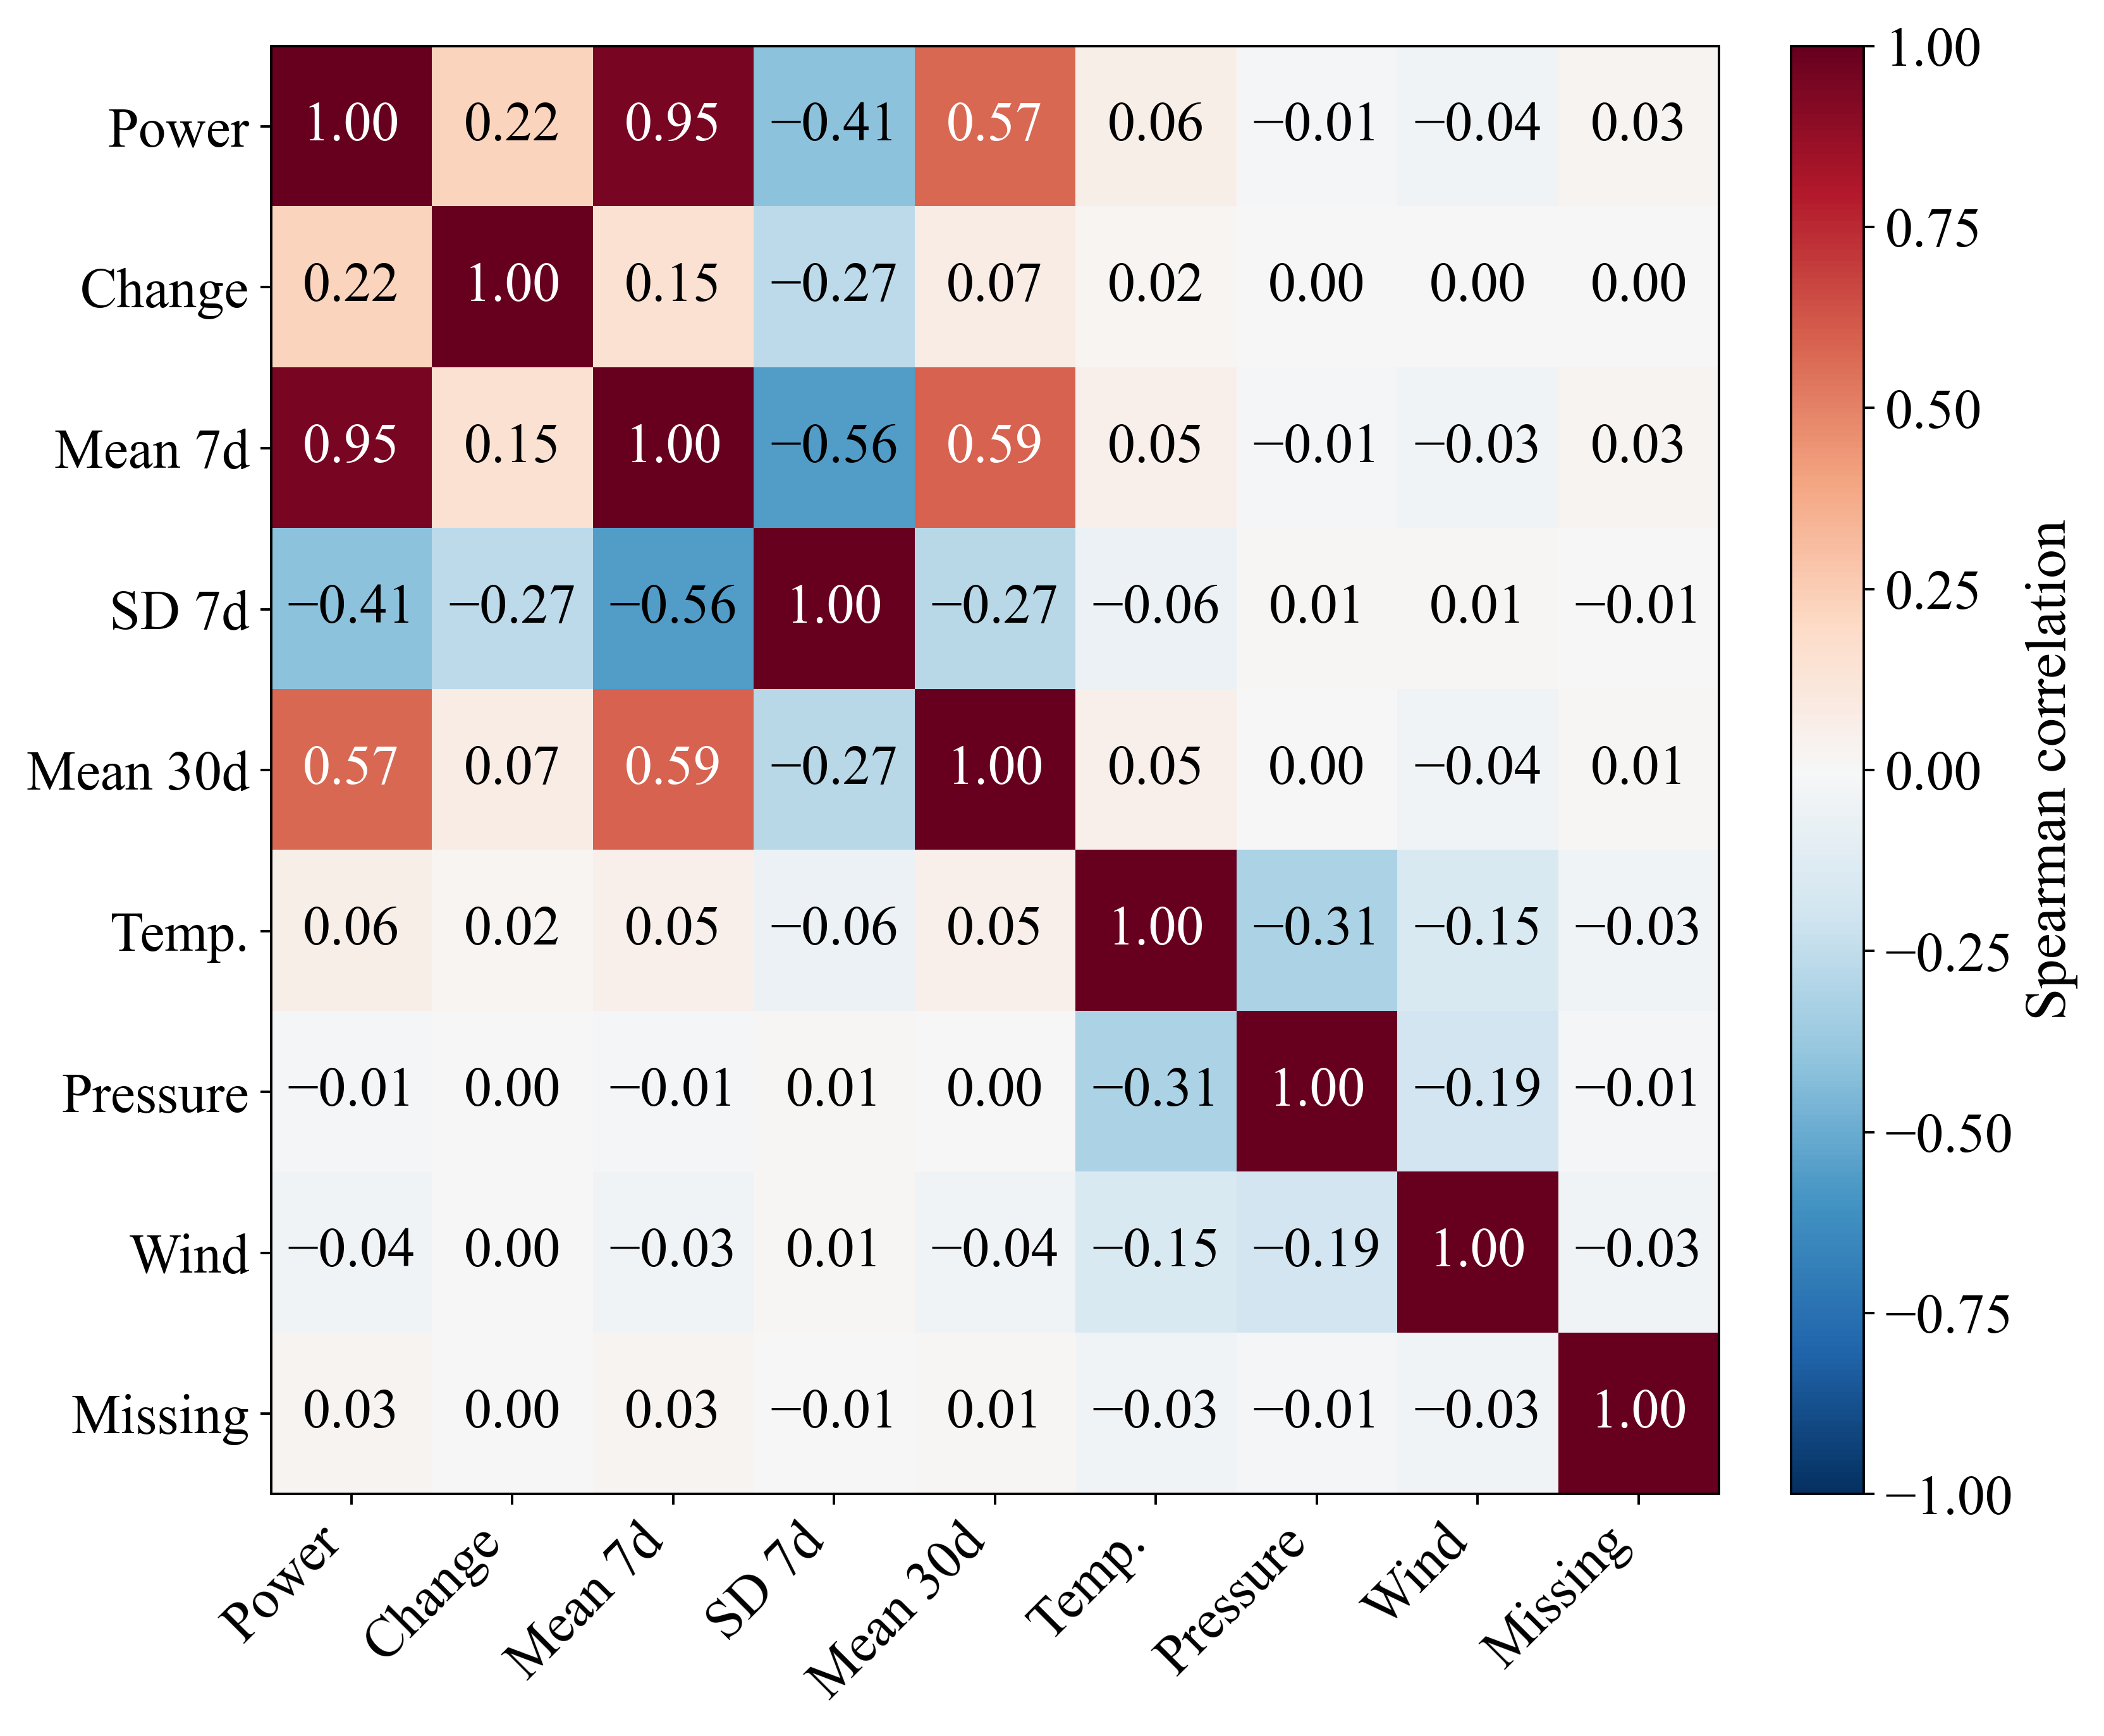

Spearman associations between group representatives, calculated from pairwise observed values and rounded to two decimals.

In [8]:
representatives = ["power_pct", "delta_1d", "power_mean_7d", "power_std_7d", "power_mean_30d", "temp_c", "pressure_hpa", "wind_ms", "weather_missing_fraction"]
short_labels = ["Power", "Change", "Mean 7d", "SD 7d", "Mean 30d", "Temp.", "Pressure", "Wind", "Missing"]
spearman = analysis[representatives].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10.5, 8.5))
values = spearman.to_numpy()
assert np.isfinite(values).all()
im = ax.imshow(values, vmin=-1, vmax=1, cmap=MATRIX_PALETTES["spearman"])
ax.set_xticks(range(len(short_labels)), short_labels, rotation=45, ha="right")
ax.set_yticks(range(len(short_labels)), short_labels)
for row in range(len(short_labels)):
    for column in range(len(short_labels)):
        value = values[row,column]
        ax.text(column, row, f"{0 if abs(value)<.005 else value:.2f}".replace("-","−"), ha="center", va="center", fontsize=18, color=annotation_color(im,value))
fig.colorbar(im, ax=ax, fraction=.046, pad=.04, label="Spearman correlation")
publication_figure(fig, "nb02_spearman_features", spearman.reset_index(names="Feature"), "Spearman associations between group representatives, calculated from pairwise observed values and rounded to two decimals.")


In [9]:
from sklearn.metrics import mutual_info_score
mi_columns = ["power_pct","delta_1d","delta_3d","power_range_7d","power_std_7d","power_mean_30d",
    "zero_run_days","temp_c","wind_ms","pressure_hpa","precip_mm","weather_missing_fraction",
    "reactor_is_pwr","dayofyear_sin","dayofyear_cos"]


def discretize_train(values, name):
    """Fixed physical bins where meaningful; otherwise training deciles, missing = separate category."""
    if name == "power_pct" or name.startswith(("power_mean","power_min")):
        edges = [-np.inf,0,10,50,90,95,99,100,np.inf]
    elif name.startswith("delta"):
        edges = [-np.inf,-50,-20,-5,-2,0,2,5,20,50,np.inf]
    elif name.startswith("power_range"):
        edges = [-np.inf,0,2,10,20,50,90,100,np.inf]
    elif name.startswith("power_std"):
        edges = [-np.inf,0,.5,2,5,10,20,50,np.inf]
    elif name in ["zero_run_days","days_since_change"]:
        edges = [-np.inf,0,1,3,7,14,30,90,365,np.inf]
    else:
        edges = None
    if edges is not None:
        return pd.cut(values,edges,labels=False).fillna(-1).astype(int), "Fixed physical intervals"
    if values.nunique() <= 32:
        return pd.Series(pd.factorize(values,sort=True)[0],index=values.index), "Observed discrete categories"
    return pd.qcut(values,10,labels=False,duplicates="drop").fillna(-1).astype(int), "Training deciles"



In [10]:
mi_codes = pd.DataFrame({name:discretize_train(analysis[name],name)[0] for name in mi_columns},index=analysis.index)
mi_cohorts = {"All train":pd.Series(True,index=analysis.index),
    **{str(year):analysis.date.dt.year.eq(year) for year in range(2019,2023)},
    "Hard controls":analysis.target.eq(1)|analysis.control_kind.eq("Documented non-SCRAM")}
target_information, mi_source_rows = pd.DataFrame(index=mi_columns,columns=mi_cohorts,dtype=float), []
for cohort,mask in mi_cohorts.items():
    y = analysis.loc[mask,"target"].astype(int)
    entropy_y = mutual_info_score(y,y)
    for name in mi_columns:
        information = mutual_info_score(y,mi_codes.loc[mask,name])
        assert -1e-12 <= information <= entropy_y+1e-12
        target_information.loc[name,cohort] = information/entropy_y
        mi_source_rows.append({"feature":name,"cohort":cohort,"n":len(y),"positive_days":int(y.sum()),
            "MI_nat":information,"label_entropy_nat":entropy_y,"fraction_label_entropy":information/entropy_y})
mi_source = pd.DataFrame(mi_source_rows)
mi_source.to_csv(TABLES / "nb02_target_information_details.csv",index=False)
mi_cohort_sizes = mi_source.groupby("cohort",sort=False).agg(n=("n","first"),
    positive_days=("positive_days","first"),label_entropy_nat=("label_entropy_nat","first")).reset_index()
scientific_table(mi_cohort_sizes,"nb02_mi_cohort_sizes",
    "Cohort size and rare-label entropy underlying the mutual-information matrix")


**Cohort size and rare-label entropy underlying the mutual-information matrix**

cohort,n,positive_days,label_entropy_nat
All train,118966,172,0.0109
2019,30326,51,0.0124
2020,29457,47,0.0119
2021,29681,37,0.0096
2022,29502,37,0.0096
Hard controls,896,172,0.4891


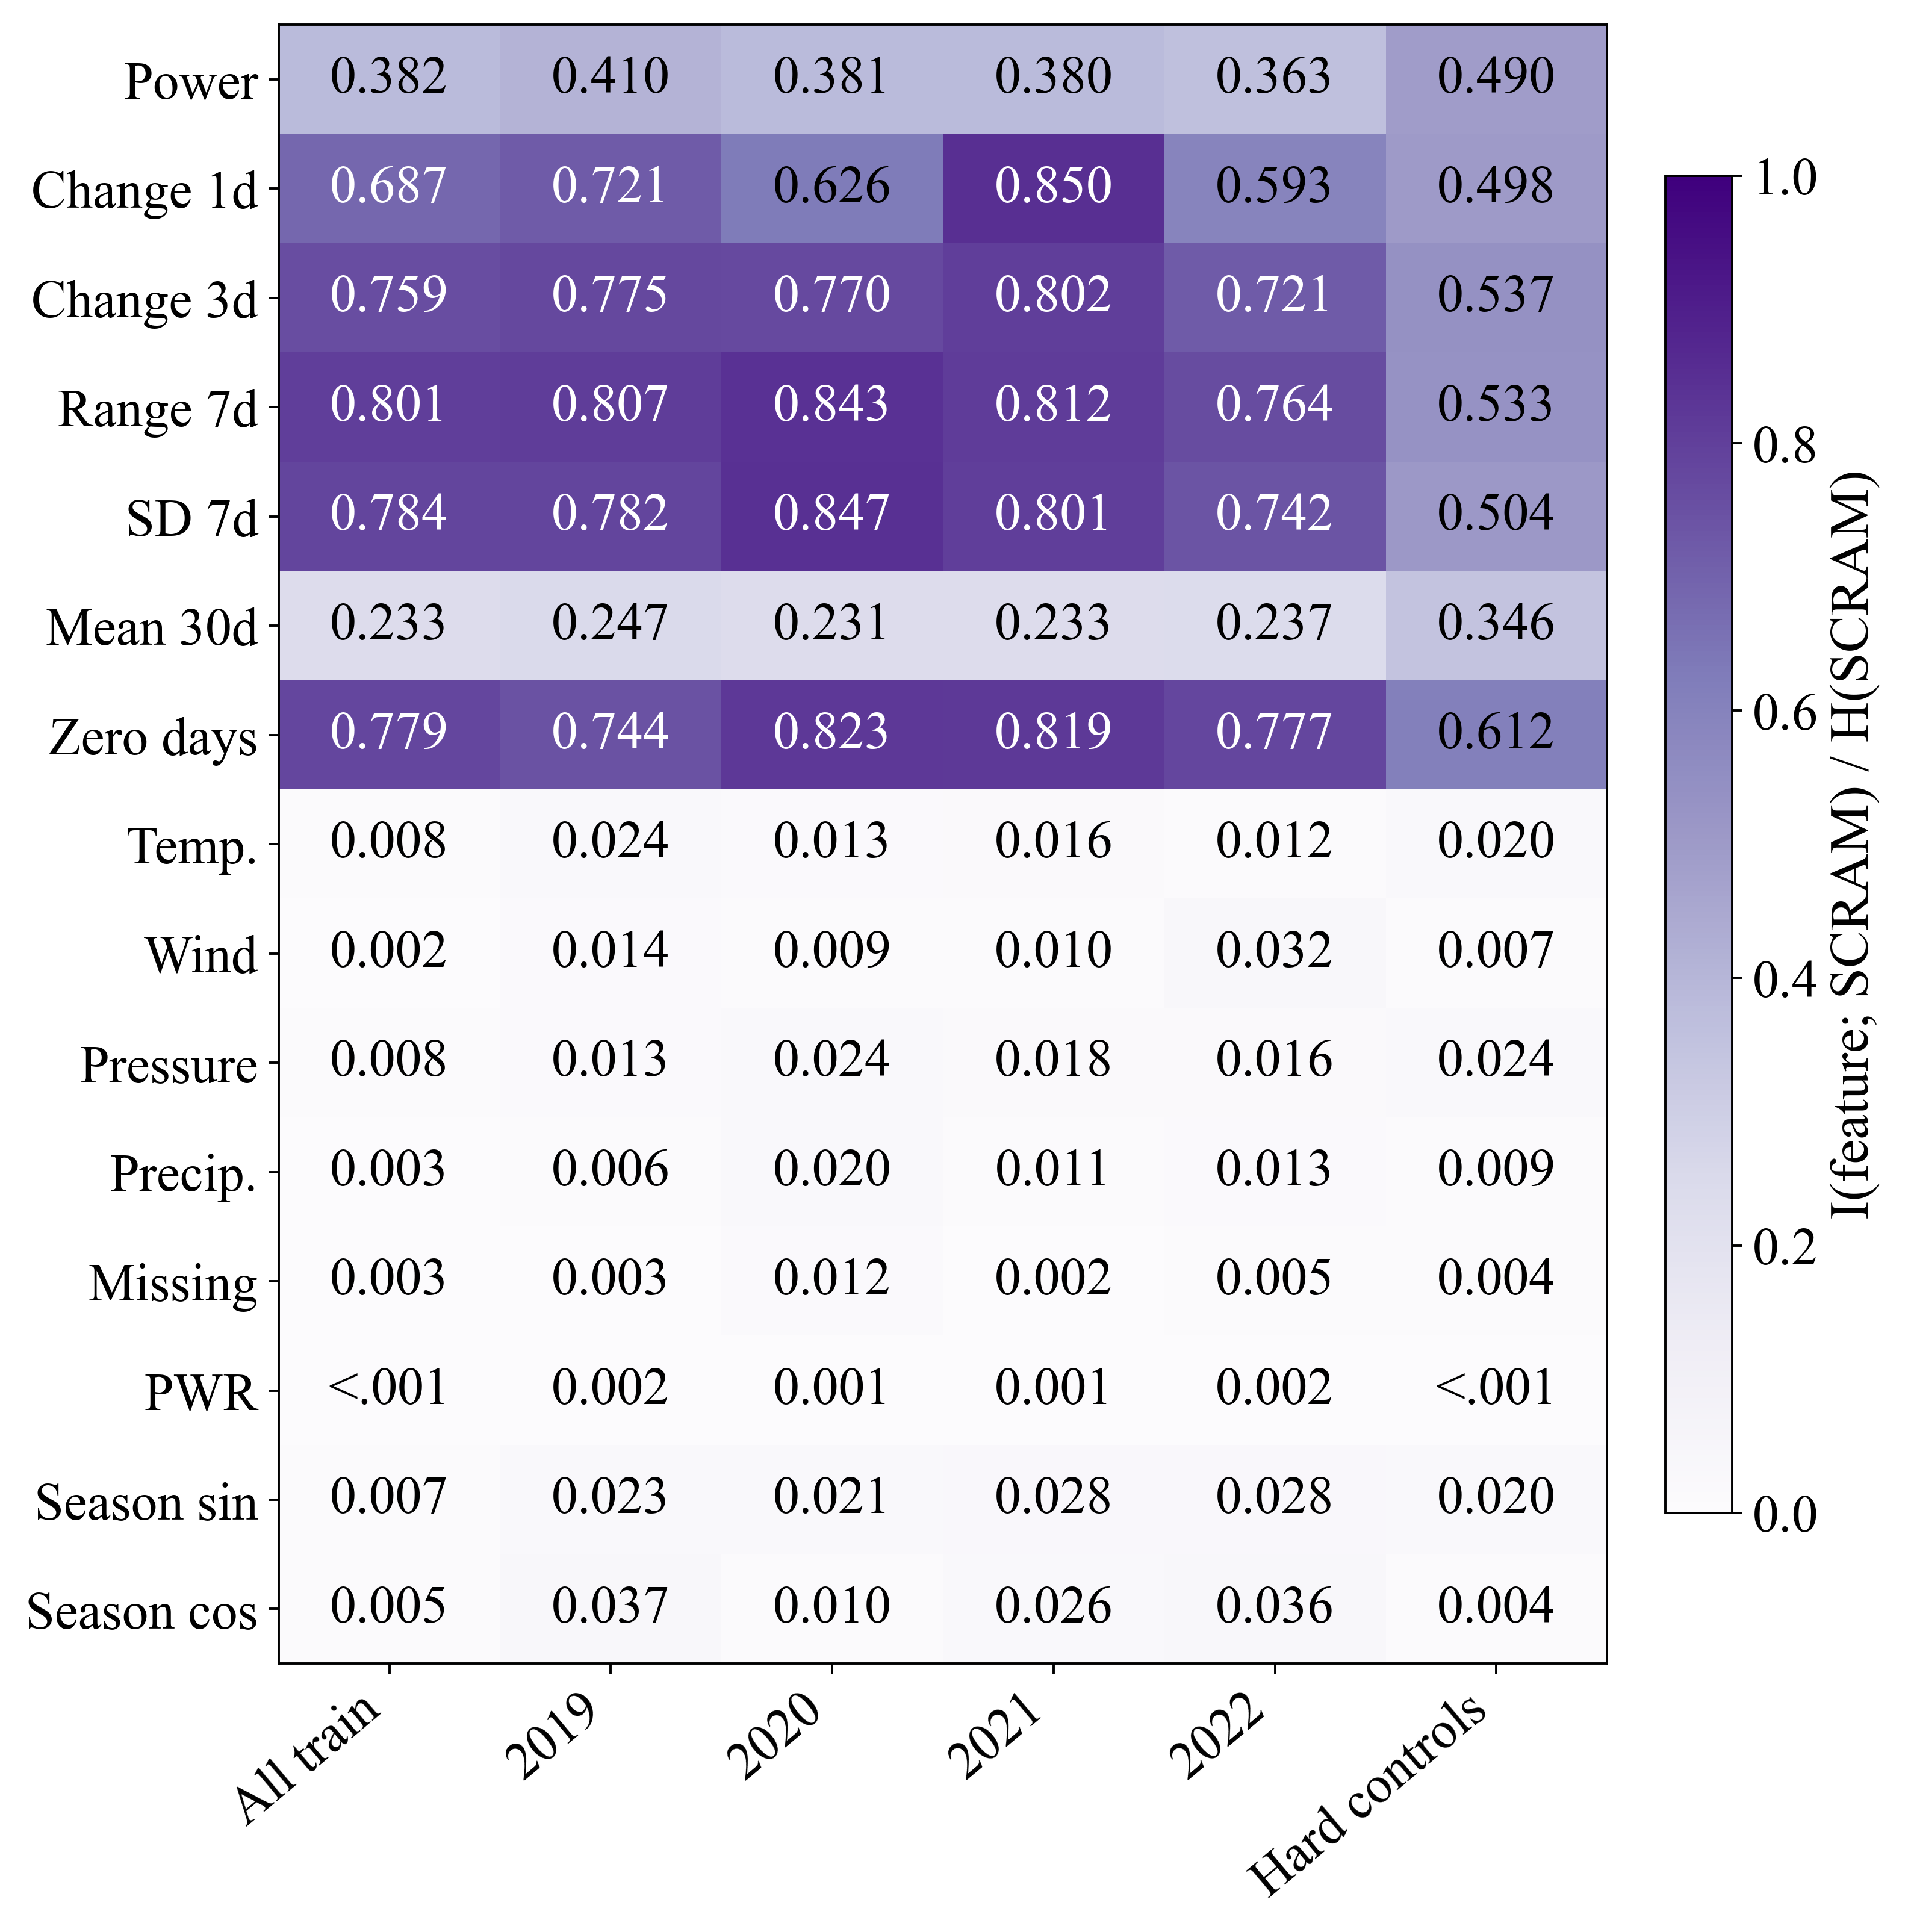

MI/H for SCRAM by year and control composition. <.001 denotes a positive fraction below 0.001. Hard controls combine documented non-SCRAM observations with the same positive days; bin boundaries are fixed from training data.

In [11]:
target_labels = ["Power","Change 1d","Change 3d","Range 7d","SD 7d","Mean 30d","Zero days",
    "Temp.","Wind","Pressure","Precip.","Missing","PWR","Season sin","Season cos"]
assert np.isfinite(target_information.to_numpy()).all()
fig,ax = plt.subplots(figsize=(8.9,10.1))
image = ax.imshow(target_information,aspect="auto",vmin=0,vmax=1,cmap=MATRIX_PALETTES["target_mi"])
ax.set_xticks(range(len(mi_cohorts)),list(mi_cohorts),rotation=40,ha="right")
ax.set_yticks(range(len(target_labels)),target_labels)
for row in range(len(target_labels)):
    for column in range(len(mi_cohorts)):
        value = target_information.iloc[row,column]
        ax.text(column,row,matrix_number(value,3),ha="center",va="center",fontsize=18,
                color=annotation_color(image,value))
fig.colorbar(image,ax=ax,fraction=.046,pad=.04,label="I(feature; SCRAM) / H(SCRAM)")
publication_figure(fig,"nb02_target_mi_matrix",target_information.reset_index(names="Feature"),
    "MI/H for SCRAM by year and control composition. <.001 denotes a positive fraction below 0.001. Hard controls combine documented non-SCRAM observations with the same positive days; bin boundaries are fixed from training data.")


### Pairwise mutual information

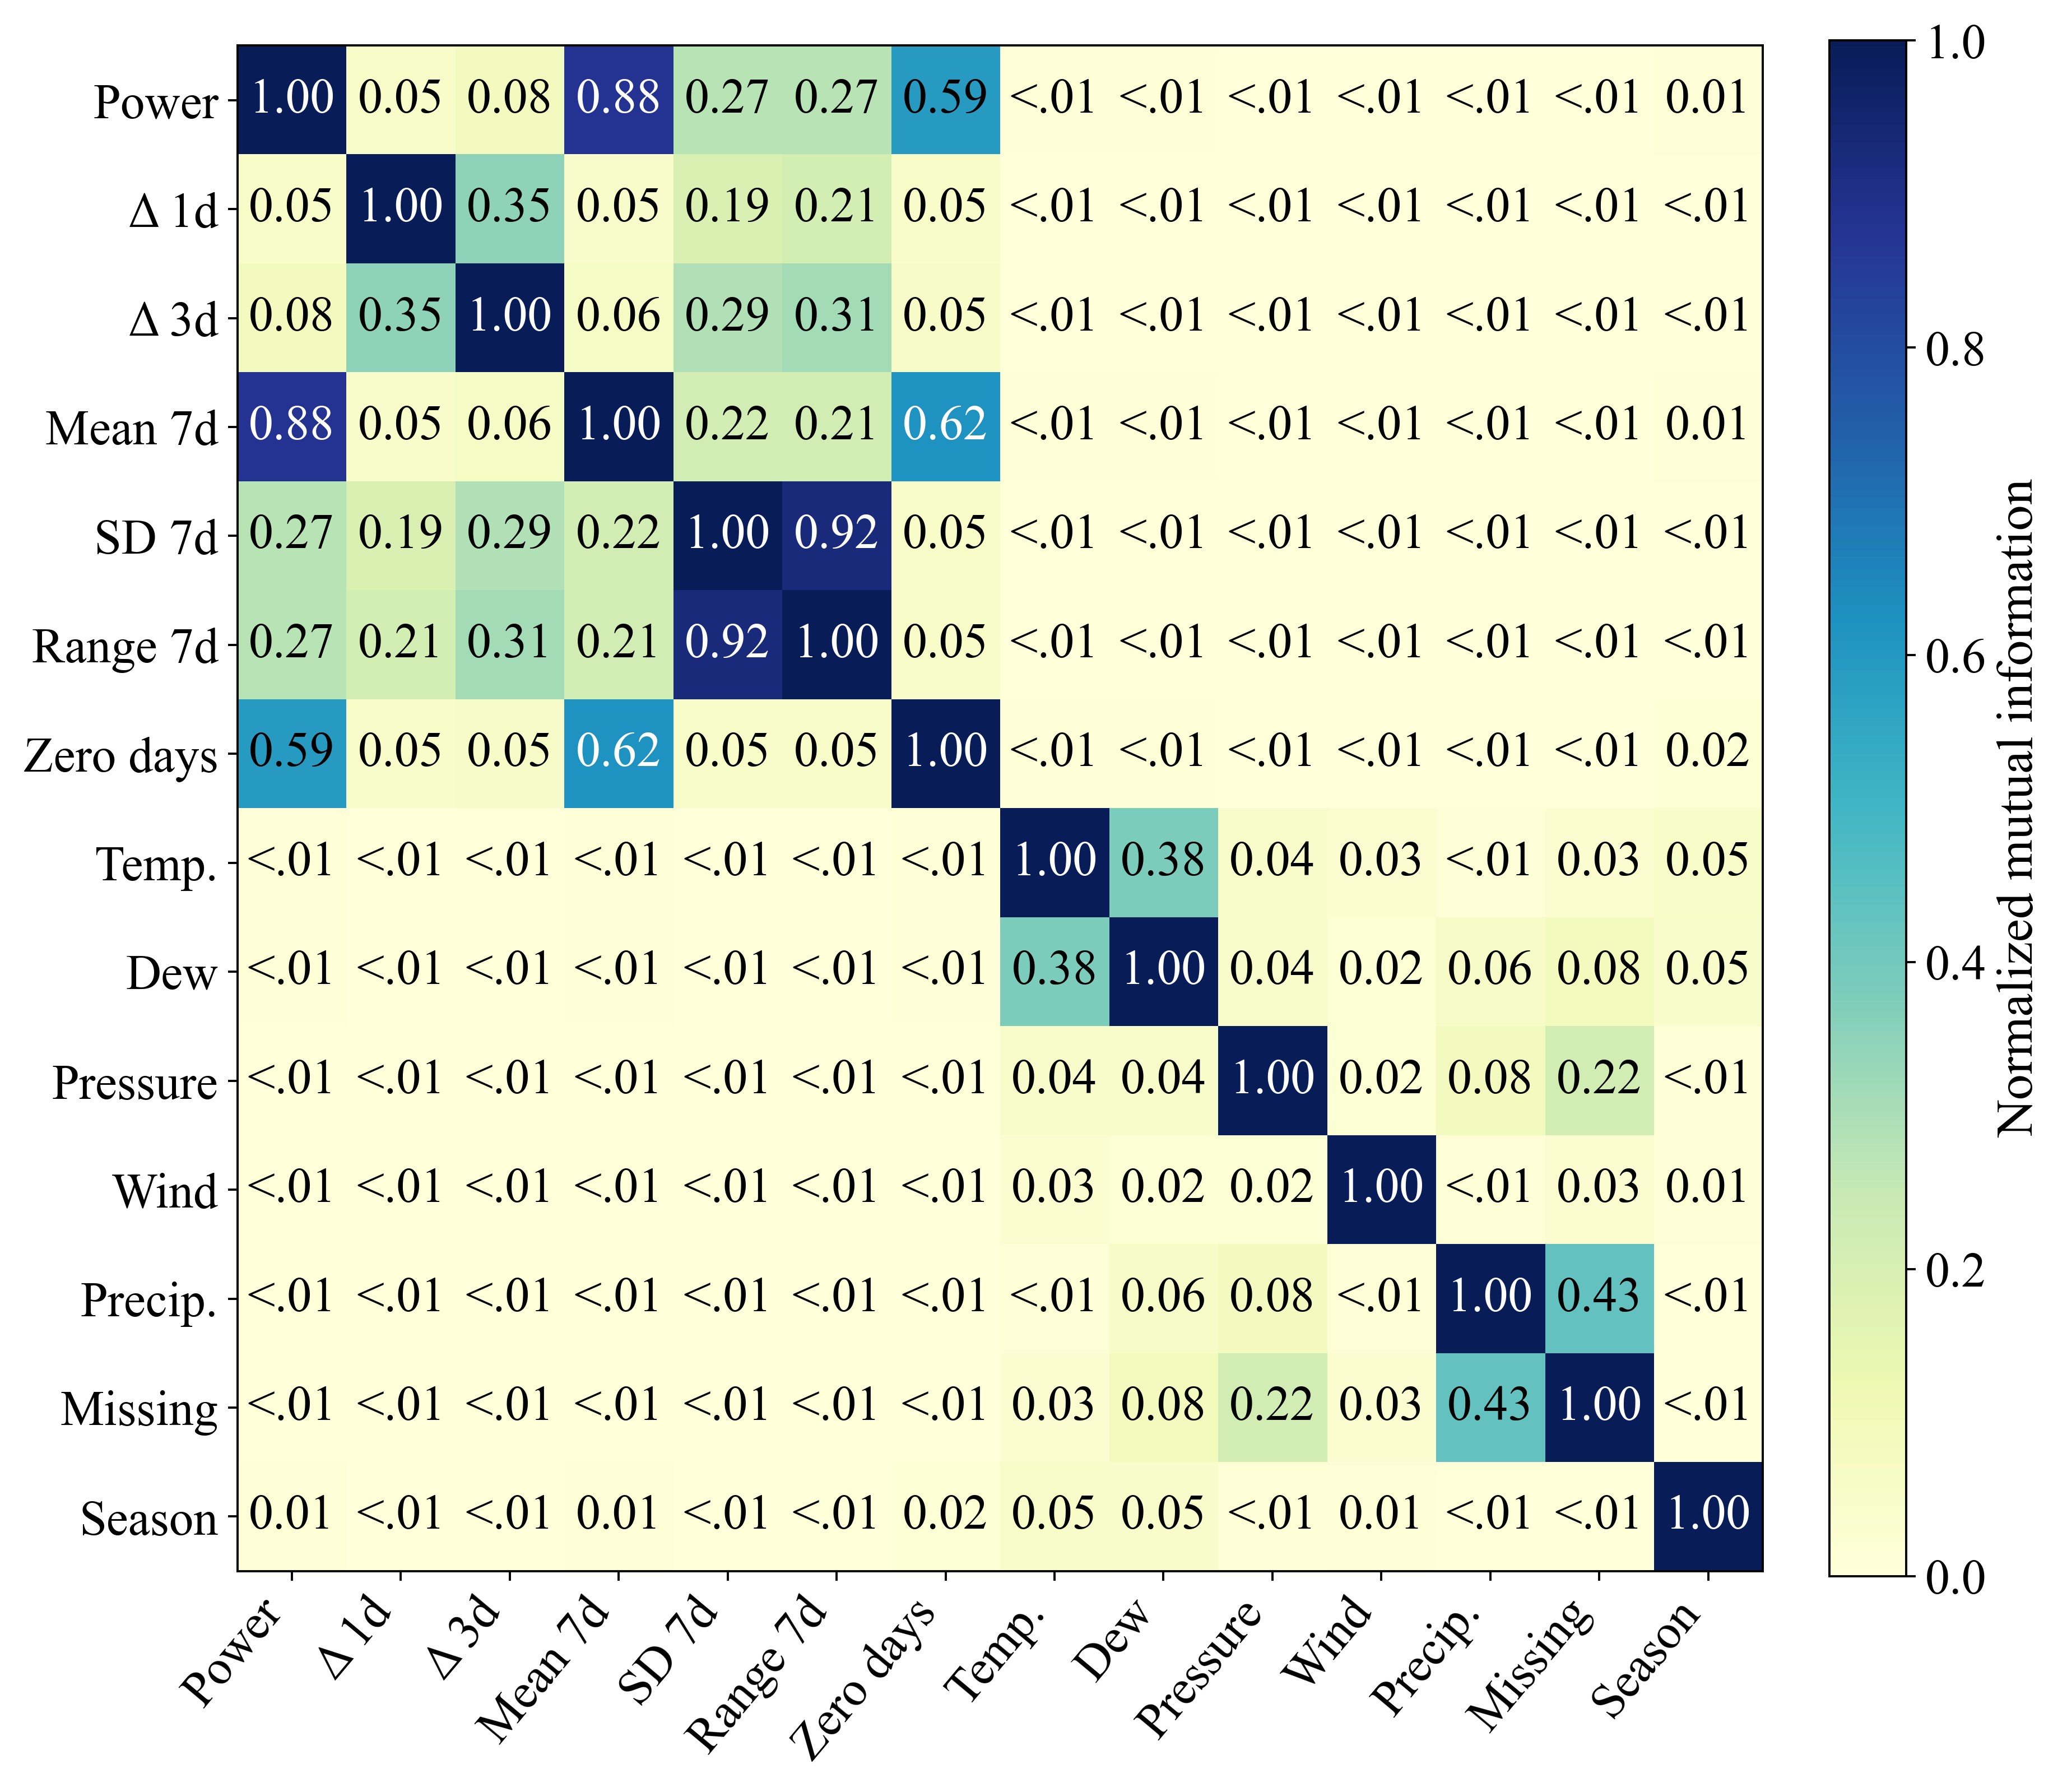

Pairwise NMI across 118,966 training days and 14 features. <.01 denotes a positive value below 0.01. Diagonal values equal 1 for nonconstant variables.

In [12]:
dependency_columns = ["power_pct","delta_1d","delta_3d","power_mean_7d","power_std_7d",
    "power_range_7d","zero_run_days","temp_c","dewpoint_c","pressure_hpa","wind_ms","precip_mm",
    "weather_missing_fraction","dayofyear_sin"]
dependency_labels = ["Power","Δ 1d","Δ 3d","Mean 7d","SD 7d","Range 7d","Zero days",
    "Temp.","Dew","Pressure","Wind","Precip.","Missing","Season"]
dependency_codes = pd.DataFrame({name:discretize_train(analysis[name],name)[0] for name in dependency_columns},index=analysis.index)
pair_mi = pd.DataFrame(np.nan,index=dependency_columns,columns=dependency_columns)
normalized_mi = pair_mi.copy()
entropy = {name:mutual_info_score(dependency_codes[name],dependency_codes[name]) for name in dependency_columns}
for i,first in enumerate(dependency_columns):
    for second in dependency_columns[i:]:
        information = mutual_info_score(dependency_codes[first],dependency_codes[second])
        pair_mi.loc[first,second] = pair_mi.loc[second,first] = information
        denominator = entropy[first]+entropy[second]
        value = 2*information/denominator if denominator>0 else np.nan
        normalized_mi.loc[first,second] = normalized_mi.loc[second,first] = value
assert np.nanmin(normalized_mi.to_numpy())>=-1e-12 and np.nanmax(normalized_mi.to_numpy())<=1+1e-12
pair_mi.reset_index(names="Feature").to_csv(TABLES / "nb02_pairwise_mi_nat.csv",index=False)
fig = matrix_canvas(normalized_mi,dependency_labels,"Normalized mutual information",cmap=MATRIX_PALETTES["pairwise_mi"])
publication_figure(fig,"nb02_pairwise_mi_matrix",normalized_mi.reset_index(names="Feature"),
    f"Pairwise NMI across {len(analysis):,} training days and 14 features. <.01 denotes a positive value below 0.01. Diagonal values equal 1 for nonconstant variables.")


### Nonlinear dependence: distance correlation

In [13]:
def distance_correlation(first, second):
    """Biased empirical distance correlation, computed on pairwise complete observations."""
    valid = np.isfinite(first)&np.isfinite(second)
    x,y = np.asarray(first)[valid],np.asarray(second)[valid]
    if len(x)<4 or np.ptp(x)==0 or np.ptp(y)==0:
        return np.nan,len(x)
    a,b = np.abs(x[:,None]-x[None,:]),np.abs(y[:,None]-y[None,:])
    a -= a.mean(axis=0)[None,:]+a.mean(axis=1)[:,None]-a.mean()
    b -= b.mean(axis=0)[None,:]+b.mean(axis=1)[:,None]-b.mean()
    covariance_squared = np.mean(a*b)
    denominator = np.sqrt(np.mean(a*a)*np.mean(b*b))
    return np.sqrt(np.clip(covariance_squared/denominator,0,1)),len(x)


import dcor
verification_pair = analysis[["power_pct","power_mean_7d"]].dropna().iloc[::97].iloc[:1000]
direct,_ = distance_correlation(verification_pair.power_pct.to_numpy(),verification_pair.power_mean_7d.to_numpy())
fast = dcor.distance_correlation(verification_pair.power_pct.to_numpy(),verification_pair.power_mean_7d.to_numpy(),method="avl")
assert np.isclose(direct,fast,rtol=1e-9,atol=1e-10)


def full_distance_matrix(frame, columns):
    matrix = pd.DataFrame(np.nan,index=columns,columns=columns)
    counts = pd.DataFrame(0,index=columns,columns=columns)
    for i,first in enumerate(columns):
        for second in columns[i:]:
            pair = frame[[first,second]].dropna()
            x,y = pair.iloc[:,0].to_numpy(float),pair.iloc[:,1].to_numpy(float)
            value = float(dcor.distance_correlation(x,y,method="avl")) if np.ptp(x)>0 and np.ptp(y)>0 else np.nan
            matrix.loc[first,second] = matrix.loc[second,first] = value
            counts.loc[first,second] = counts.loc[second,first] = len(pair)
    return matrix,counts



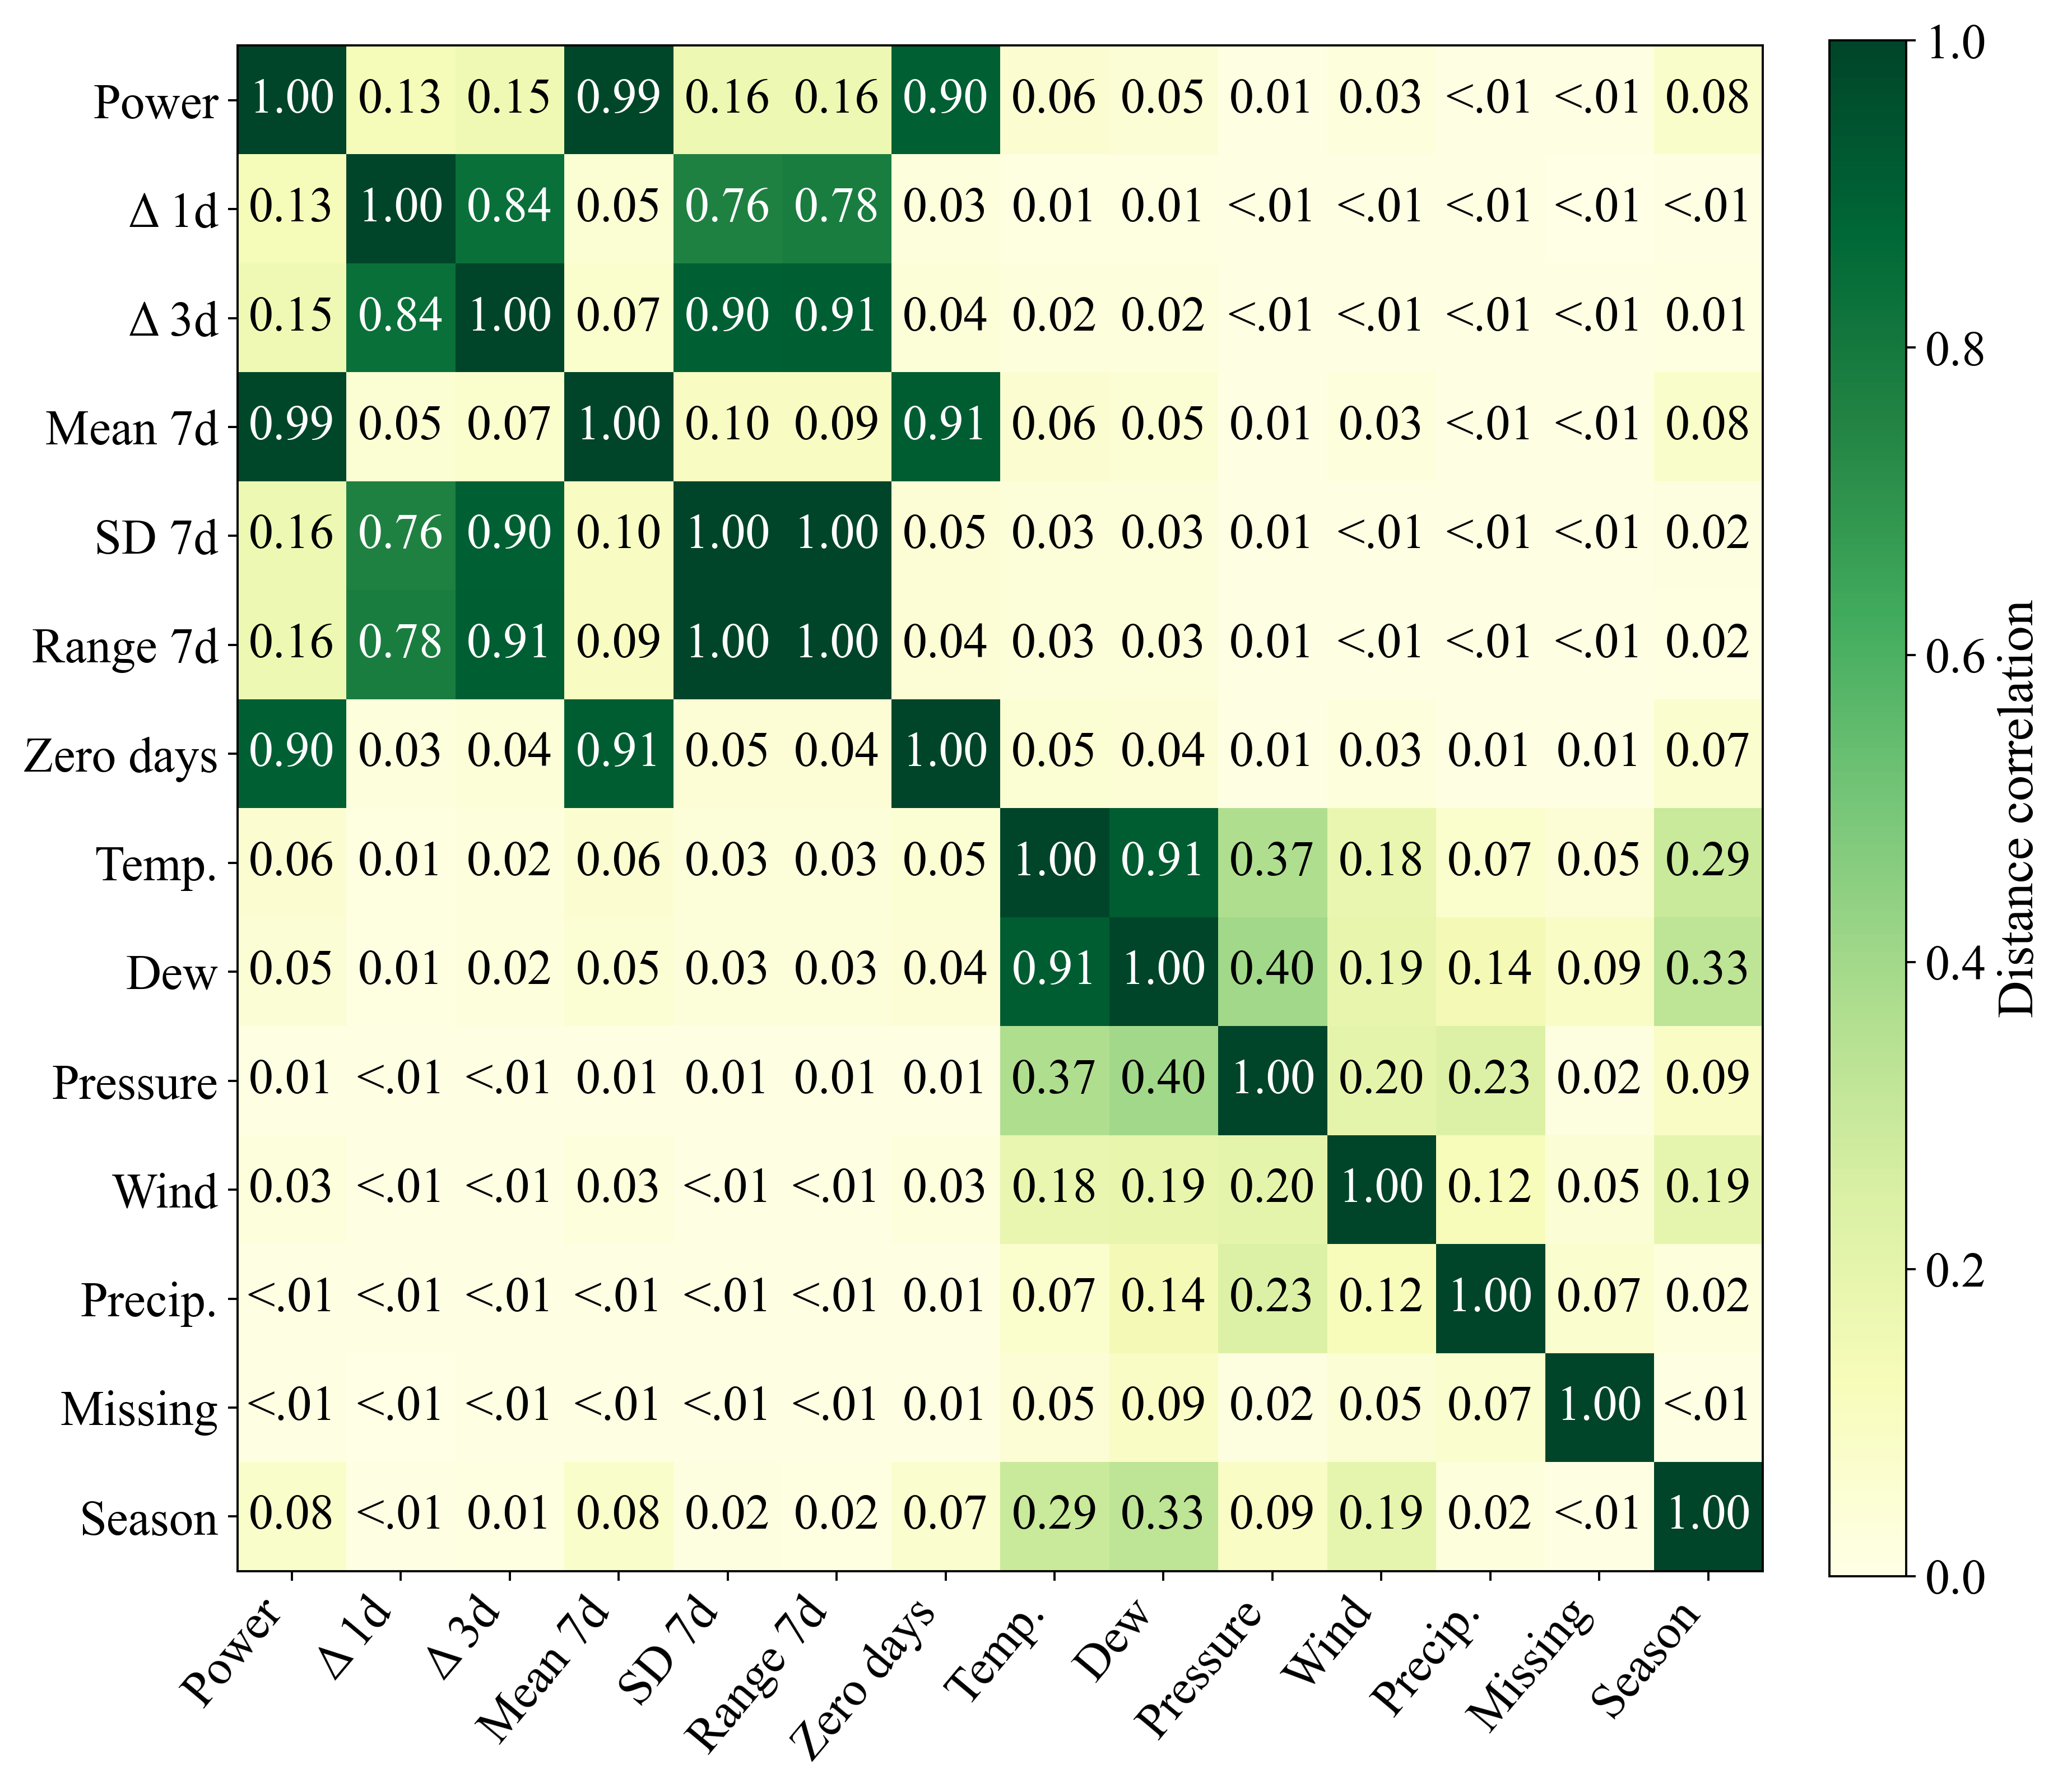

dCor across the full training period; pairwise n ranges from 69,941 to 118,966. Scale 0–1; <.01 denotes a positive value below 0.01. Missing values are excluded pairwise.

In [14]:
dcor_matrix,dcor_counts = full_distance_matrix(analysis,dependency_columns)
assert np.allclose(dcor_matrix.to_numpy(),dcor_matrix.to_numpy().T,equal_nan=True)
fig = matrix_canvas(dcor_matrix,dependency_labels,"Distance correlation",cmap=MATRIX_PALETTES["nonlinear"])
dcor_counts.reset_index(names="Feature").to_csv(TABLES / "nb02_dcor_pair_counts.csv",index=False)
publication_figure(fig,"nb02_nonlinear_dcor_matrix",dcor_matrix.reset_index(names="Feature"),
    f"dCor across the full training period; pairwise n ranges from {dcor_counts.to_numpy().min():,} to {dcor_counts.to_numpy().max():,}. Scale 0–1; <.01 denotes a positive value below 0.01. Missing values are excluded pairwise.")


In [15]:
stability_pairs = [("power_pct","power_mean_7d"),("power_std_7d","power_range_7d"),
    ("delta_1d","delta_3d"),("temp_c","dewpoint_c"),("power_pct","temp_c"),
    ("delta_1d","wind_ms"),("power_range_7d","temp_c"),("weather_missing_fraction","precip_mm")]
stability_rows = []
for first,second in stability_pairs:
    row = {"Feature A":first,"Feature B":second}
    for year in range(2019,2023):
        pair = analysis.loc[analysis.date.dt.year.eq(year),[first,second]].dropna()
        row[str(year)] = float(dcor.distance_correlation(pair.iloc[:,0].to_numpy(float),pair.iloc[:,1].to_numpy(float),method="avl"))
    stability_rows.append(row)
scientific_table(pd.DataFrame(stability_rows),"nb02_dcor_year_stability",
    "Nonlinear associations by year: stability and variation")
adjusted_nonlinear = []
for weather in weather_names:
    pair = adjusted[["power_pct",weather]].dropna()
    adjusted_nonlinear.append({"Weather":weather,"Site days":len(pair),
        "Site-month adjusted dCor":float(dcor.distance_correlation(pair.power_pct.to_numpy(float),pair[weather].to_numpy(float),method="avl"))})
scientific_table(pd.DataFrame(adjusted_nonlinear),"nb02_adjusted_nonlinear_weather",
    "Nonlinear weather associations after removing site–month means; these are not causal estimates")


**Nonlinear associations by year: stability and variation**

Feature A,Feature B,2019,2020,2021,2022
power_pct,power_mean_7d,0.9910,0.9918,0.9922,0.9935
power_std_7d,power_range_7d,0.9973,0.9976,0.9976,0.9967
delta_1d,delta_3d,0.8841,0.8010,0.8708,0.7778
temp_c,dewpoint_c,0.9216,0.9047,0.9038,0.9118
power_pct,temp_c,0.0484,0.0605,0.0610,0.0707
delta_1d,wind_ms,0.0096,0.0085,0.0094,0.0113
power_range_7d,temp_c,0.0433,0.0195,0.0576,0.0172
weather_missing_fraction,precip_mm,0.0780,0.0690,0.0741,0.0627


**Nonlinear weather associations after removing site–month means; these are not causal estimates**

Weather,Site days,Site-month adjusted dCor
temp_c,78428,0.0197
dewpoint_c,73618,0.0300
pressure_hpa,56014,0.0162
wind_ms,78362,0.0122
precip_mm,52848,0.0230


### Interaction between power change and zero-power duration

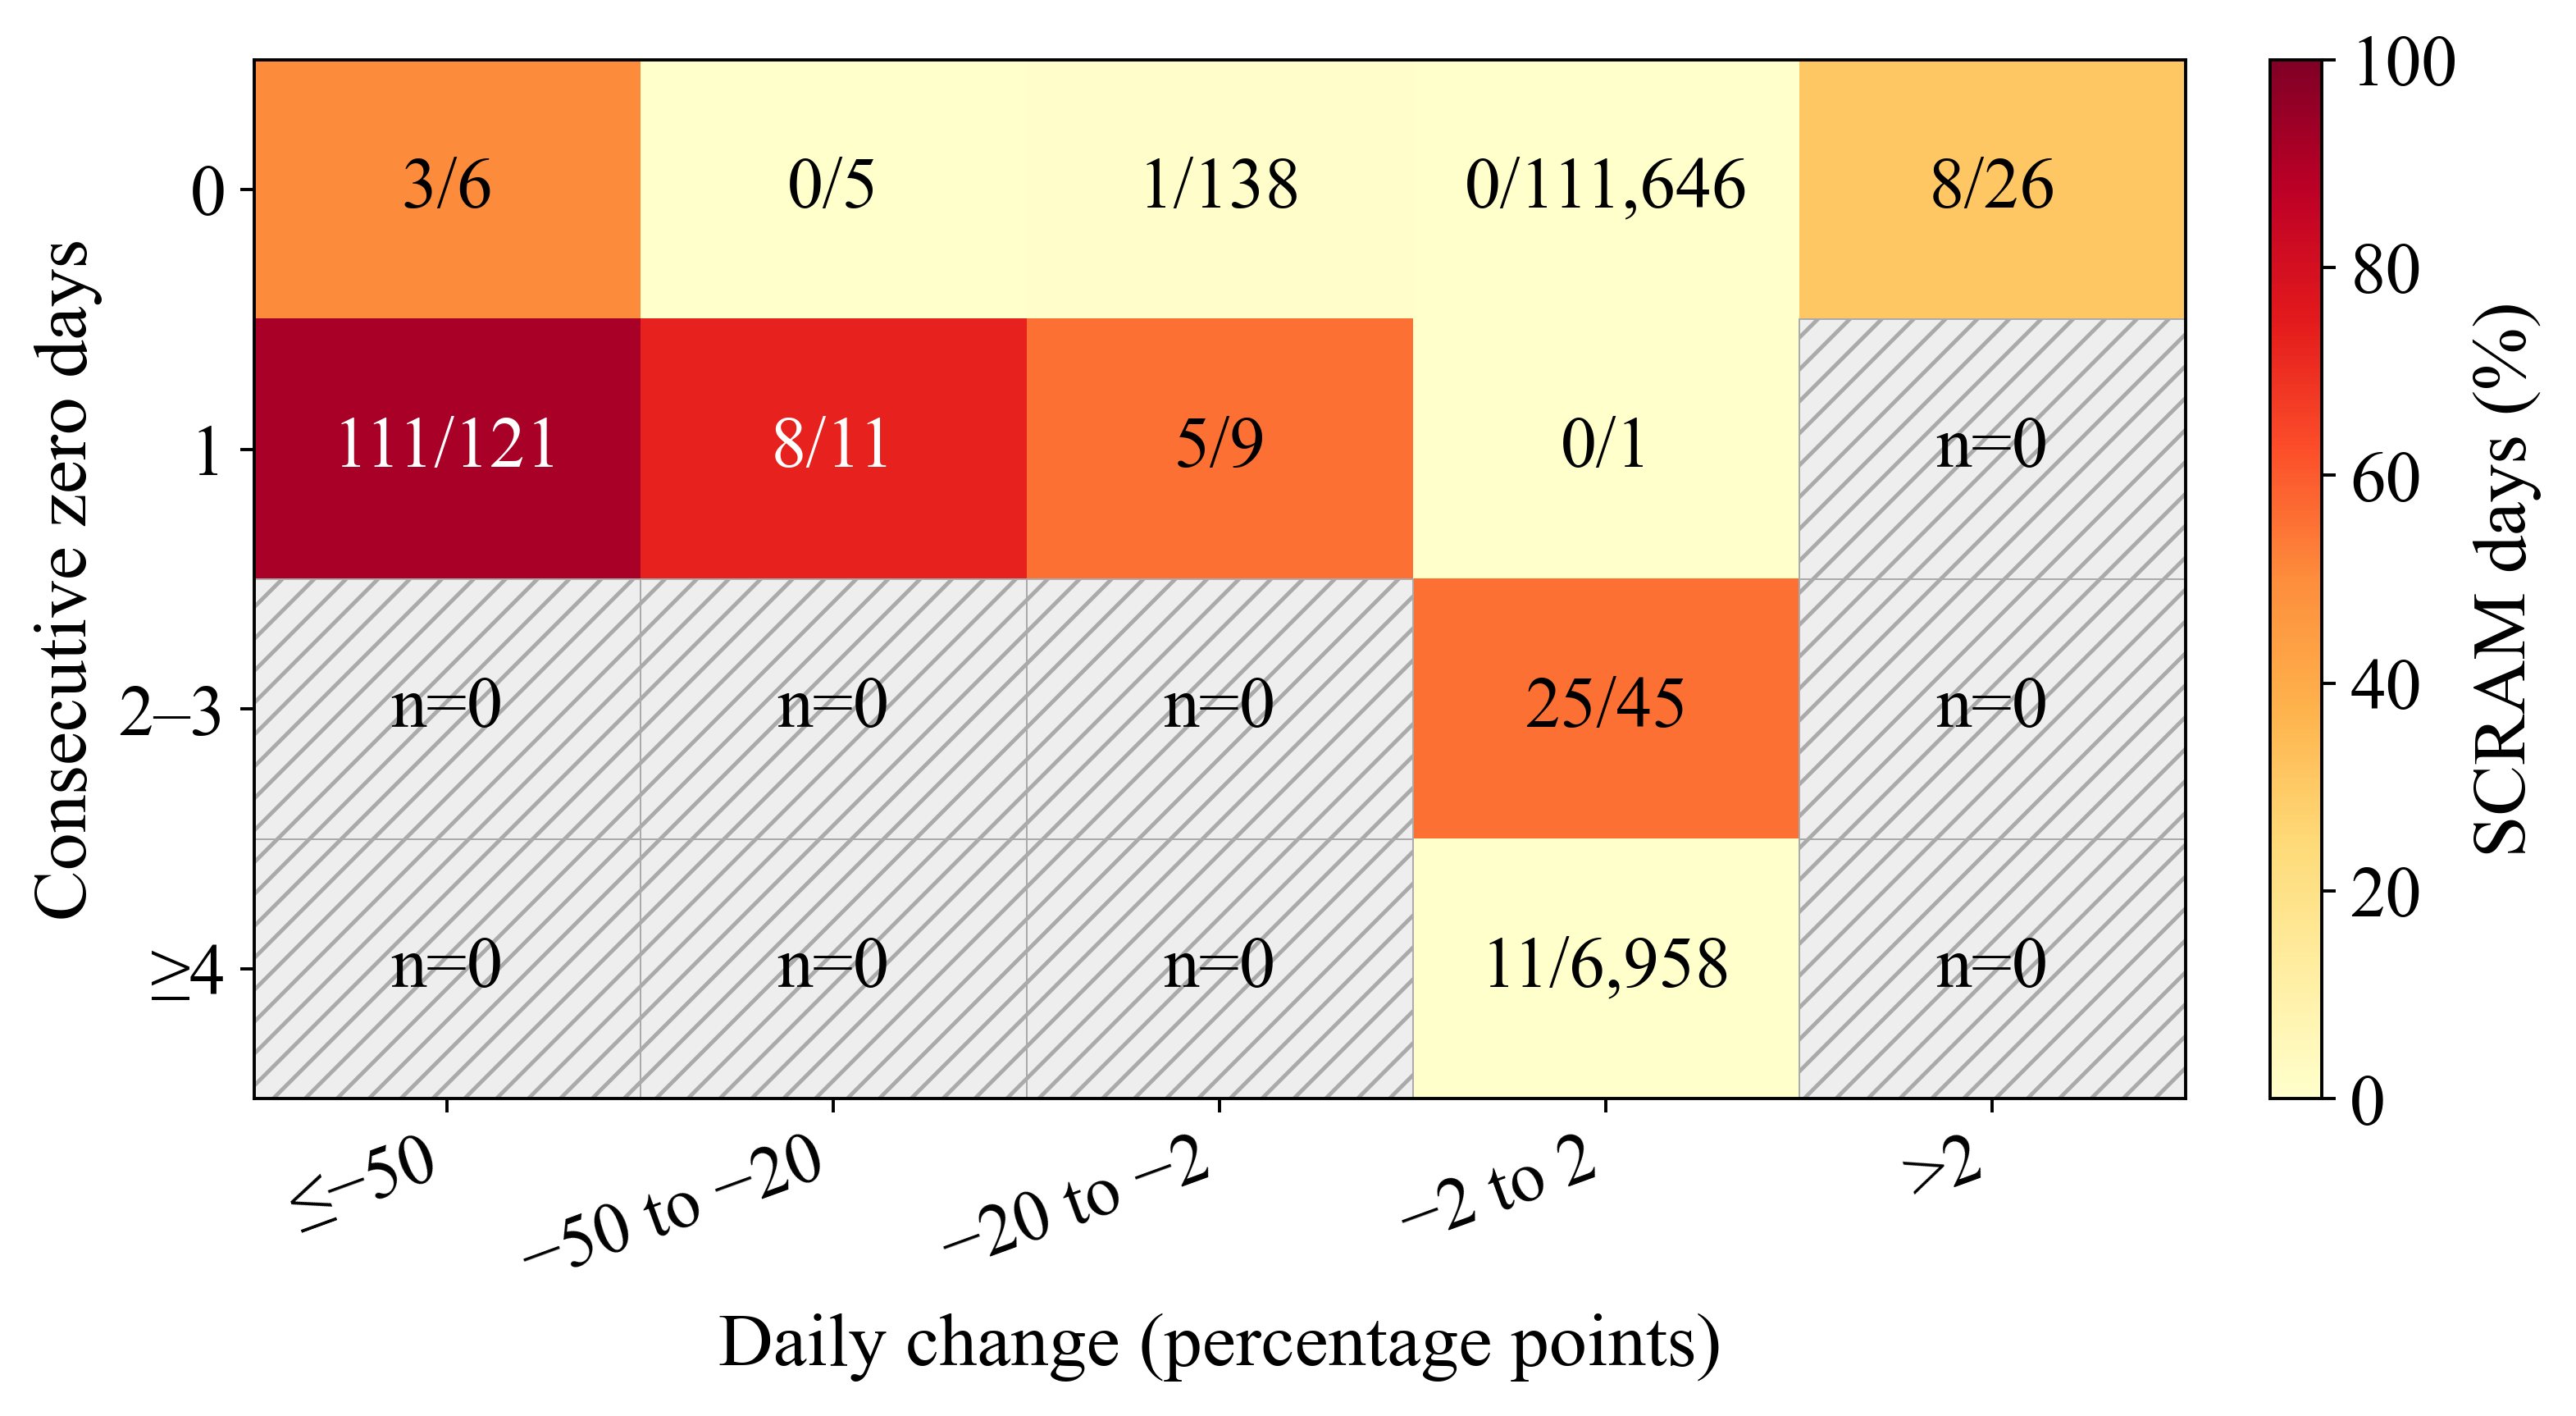

SCRAM frequency by regime; annotations show positive/all days. Gray hatching with n=0 identifies an unobserved combination with undefined frequency, not zero risk.

In [16]:
interaction = analysis[["target","delta_1d","zero_run_days"]].copy()
change_labels = ["≤−50","−50 to −20","−20 to −2","−2 to 2",">2"]
run_labels = ["0","1","2–3","≥4"]
interaction["change_bin"] = pd.cut(interaction.delta_1d,[-np.inf,-50,-20,-2,2,np.inf],labels=change_labels)
interaction["run_bin"] = pd.cut(interaction.zero_run_days,[-.5,.5,1.5,3.5,np.inf],labels=run_labels)
risk = interaction.groupby(["run_bin","change_bin"],observed=False).target.agg(n="size",positive="sum").reset_index()
risk["positive"] = risk.positive.astype(int)
risk["rate_percent"] = np.where(risk.n>0,100*risk.positive/risk.n,np.nan)
risk["observation_status"] = np.where(risk.n>0,"Observed","No observations; frequency undefined")
assert risk.n.sum() == len(interaction)
assert interaction.loc[interaction.zero_run_days.ge(2),"delta_1d"].eq(0).all()
risk_matrix = risk.pivot(index="run_bin",columns="change_bin",values="rate_percent")
fig,ax = plt.subplots(figsize=(9.5,4.7))
palette = mpl.colormaps[MATRIX_PALETTES["interactions"]].copy()
palette.set_bad("#eeeeee")
image = ax.imshow(risk_matrix,aspect="auto",vmin=0,vmax=100,cmap=palette)
ax.set_xticks(range(len(change_labels)),change_labels,rotation=20,ha="right")
ax.set_yticks(range(len(run_labels)),run_labels)
ax.set_xlabel("Daily change (percentage points)")
ax.set_ylabel("Consecutive zero days")
for r,run in enumerate(run_labels):
    for c,change in enumerate(change_labels):
        row = risk.loc[risk.run_bin.eq(run)&risk.change_bin.eq(change)].iloc[0]
        label = f"{int(row.positive)}/{int(row.n):,}" if row.n else "n=0"
        if row.n == 0:
            ax.add_patch(mpl.patches.Rectangle((c-.5,r-.5),1,1,facecolor="none",
                edgecolor="#aaaaaa",hatch="///",linewidth=.4))
        color = annotation_color(image,row.rate_percent) if row.n else "black"
        ax.text(c,r,label,ha="center",va="center",fontsize=18,color=color)
fig.colorbar(image,ax=ax,fraction=.046,pad=.04,label="SCRAM days (%)")
publication_figure(fig,"nb02_dynamic_interactions",risk,
    "SCRAM frequency by regime; annotations show positive/all days. Gray hatching with n=0 identifies an unobserved combination with undefined frequency, not zero risk.")


### Partial temporal dependence of power changes

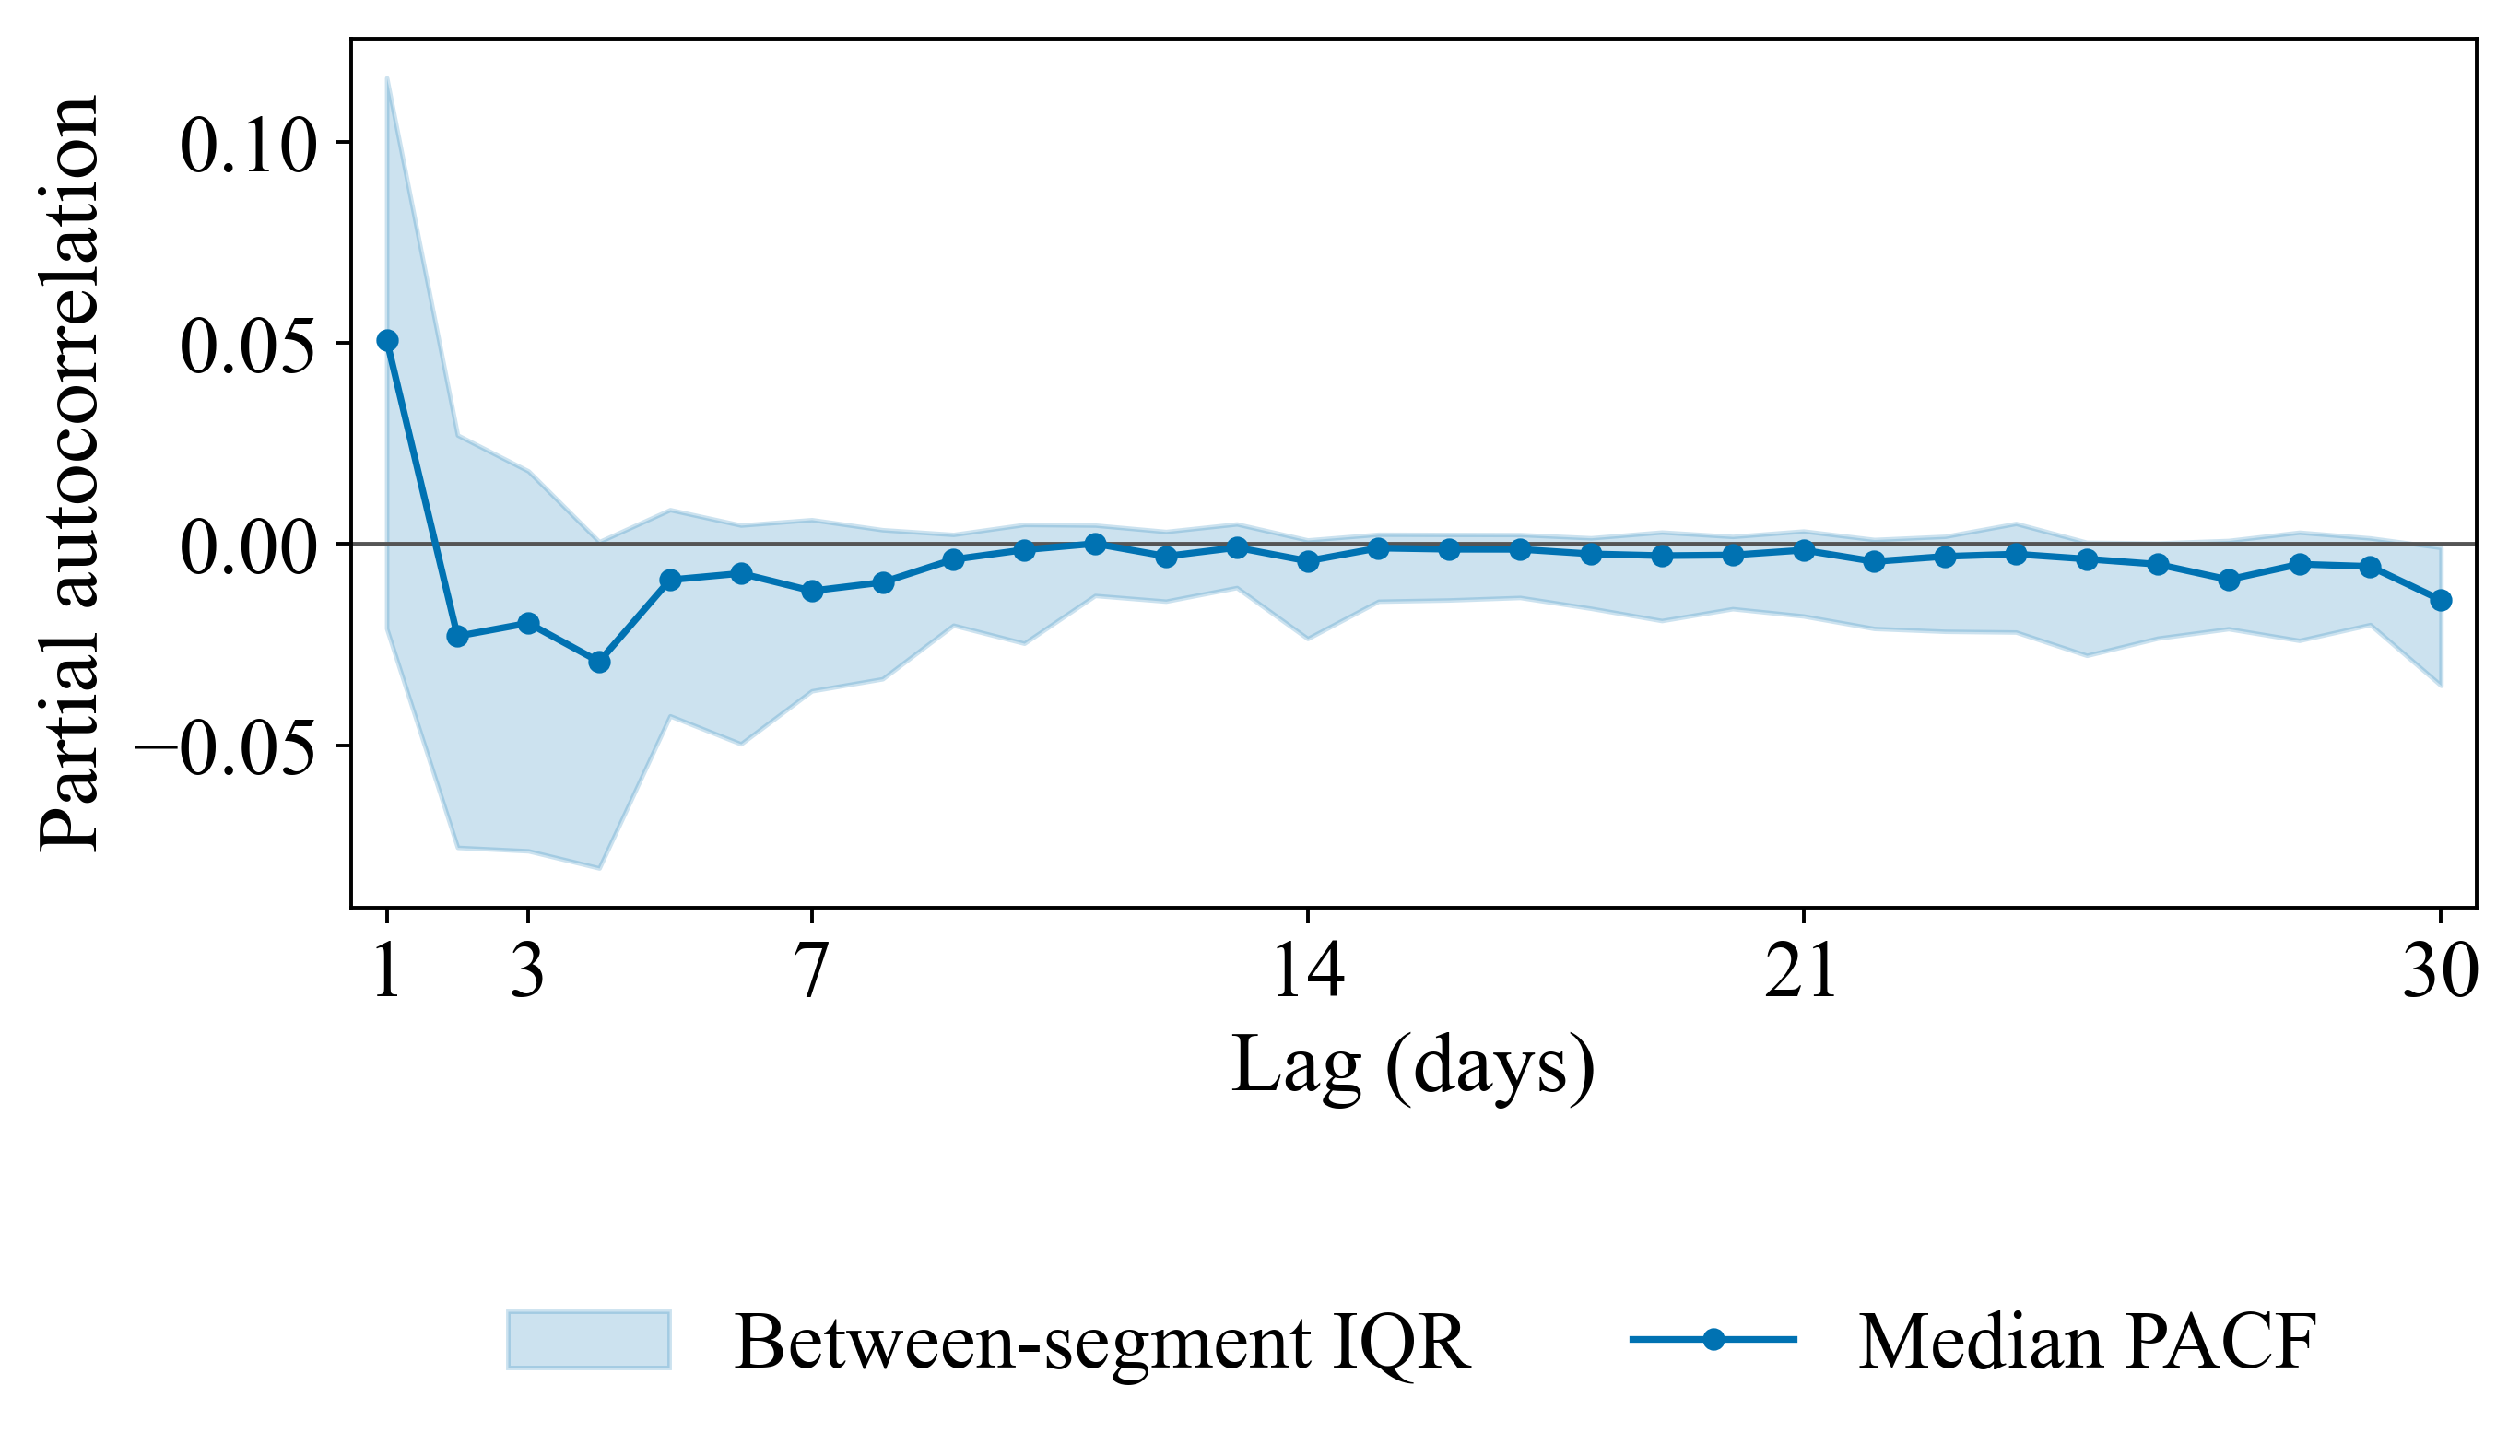

Partial memory of daily changes across 96 continuous reactor segments; 0 constant segments excluded. A strong short lag does not make longer windows unnecessary: outage duration and seasonal context require separate tests.

In [17]:
from scipy.linalg import solve_toeplitz
pacf_records, skipped_constant = [],0
memory_view = observations.loc[observations.split.eq("train")&~observations.after_recorded_shutdown]
for (reactor,segment),part in memory_view.groupby(["reactor_id","segment_index"],sort=False):
    if len(part)<365:
        continue
    values = np.diff(part.sort_values("date").power_pct.to_numpy(float))
    values -= values.mean()
    variance = np.dot(values,values)/len(values)
    if variance<=1e-12:
        skipped_constant += 1
        continue
    autocovariance = np.array([np.dot(values[lag:],values[:len(values)-lag])/len(values) for lag in range(31)])
    for lag in range(1,31):
        coefficient = solve_toeplitz(autocovariance[:lag],autocovariance[1:lag+1])[-1]
        pacf_records.append({"reactor_id":reactor,"segment":segment,"lag":lag,"PACF":coefficient})
pacf_values = pd.DataFrame(pacf_records)
pacf_summary = pacf_values.groupby("lag").PACF.agg(median="median",q25=lambda s:s.quantile(.25),q75=lambda s:s.quantile(.75),segments="size").reset_index()
fig,ax = plt.subplots(figsize=(8.5,3.5))
ax.axhline(0,color="#555555",linewidth=1)
ax.fill_between(pacf_summary.lag,pacf_summary.q25,pacf_summary.q75,color="#0072B2",alpha=.2,label="Between-segment IQR")
ax.plot(pacf_summary.lag,pacf_summary["median"],color="#0072B2",marker="o",markersize=4,label="Median PACF")
ax.set(xlabel="Lag (days)",ylabel="Partial autocorrelation",xlim=(.5,30.5))
ax.set_xticks([1,3,7,14,21,30])
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.38),ncol=2,frameon=False)
publication_figure(fig,"nb02_innovation_pacf",pacf_summary,
    f"Partial memory of daily changes across {int(pacf_summary.segments.min())} continuous reactor segments; {skipped_constant} constant segments excluded. A strong short lag does not make longer windows unnecessary: outage duration and seasonal context require separate tests.")


## Temporal windows and data splits

In [18]:
metadata_columns = ["observation_id", "reactor_id", "plant_id", "date", "episode_id", "event_episode_id", "event_id", "non_scram_event_id", "source_record_ids", "split", "label_source", "control_kind", "scram_type", "target", "eligible", "recorded_shutdown_date"]
metadata = observations[metadata_columns].copy()
metadata["full_window"] = observations.groupby(["reactor_id", "segment_index"]).date.transform(lambda s:s.diff(29).dt.days.eq(29))
metadata["model_eligible"] = metadata.eligible & metadata.full_window
metadata["target"] = metadata.target.astype("Int64")
metadata["aux_transition"] = observations.power_change.abs().ge(20).astype(int)
metadata["aux_zero_onset"] = (observations.power_pct.eq(0) & observations.groupby(["reactor_id", "segment_index"]).power_pct.shift(1).gt(0)).astype(int)
metadata["source_id"] = metadata.source_record_ids
metadata["fold"] = "not_assigned"


def chronological_split(frame: pd.DataFrame, train_end: str, eval_start: str, eval_end: str) -> tuple[np.ndarray, np.ndarray]:
    """Enforce calendar embargo, full windows, and complete episode separation."""
    train_mask = frame.model_eligible & frame.date.le(pd.Timestamp(train_end))
    evaluation_mask = frame.model_eligible & frame.date.between(pd.Timestamp(eval_start)+pd.Timedelta(days=30), pd.Timestamp(eval_end))
    earlier_episodes = set(frame.loc[frame.date.le(pd.Timestamp(train_end)), "episode_id"])
    evaluation_mask &= ~frame.episode_id.isin(earlier_episodes)
    training, evaluation = np.flatnonzero(train_mask), np.flatnonzero(evaluation_mask)
    assert set(frame.iloc[training].episode_id).isdisjoint(frame.iloc[evaluation].episode_id)
    assert frame.iloc[evaluation].date.min()-frame.iloc[training].date.max() > pd.Timedelta(days=30)
    return training, evaluation


splits = {}
for name, train_end, eval_start, eval_end in [
    ("forward_2020", "2019-12-31", "2020-01-01", "2020-12-31"),
    ("forward_2021", "2020-12-31", "2021-01-01", "2021-12-31"),
    ("forward_2022", "2021-12-31", "2022-01-01", "2022-12-31"),
    ("development", "2022-12-31", "2023-01-01", "2023-12-31"),
    ("calibration", "2023-12-31", "2024-01-01", "2024-12-31"),
    ("locked_test", "2024-12-31", "2025-01-01", "2025-12-31")]:
    training, evaluation = chronological_split(metadata, train_end, eval_start, eval_end)
    if name == "locked_test":
        training = splits["calibration"]["train"].copy()  # 2024 labels are reserved for calibration.
    splits[name] = {"train":training, "evaluation":evaluation}
    for role, indices in [("train", training), ("evaluation", evaluation)]:
        np.save(SPLITS_ROOT / f"{name}_{role}.npy", indices)
    if name.startswith("forward_"):
        metadata.loc[metadata.index[evaluation], "fold"] = name


In [19]:
physical_sites = sorted(metadata.loc[metadata.date.le("2022-12-31"), "plant_id"].unique())
site_hash = {site:int(hashlib.sha256(("RACF-transfer-42:"+site).encode()).hexdigest()[:8], 16) for site in physical_sites}
heldout_sites = {site for site, value in site_hash.items() if value % 5 == 0}
assert 5 <= len(heldout_sites) < len(physical_sites)//2
site_train = splits["development"]["train"][~metadata.iloc[splits["development"]["train"]].plant_id.isin(heldout_sites).to_numpy()]
site_eval = splits["development"]["evaluation"][metadata.iloc[splits["development"]["evaluation"]].plant_id.isin(heldout_sites).to_numpy()]
assert set(metadata.iloc[site_train].plant_id).isdisjoint(metadata.iloc[site_eval].plant_id)
splits["site_transfer"] = {"train":site_train, "evaluation":site_eval}
np.save(SPLITS_ROOT / "site_transfer_train.npy", site_train)
np.save(SPLITS_ROOT / "site_transfer_evaluation.npy", site_eval)
pd.DataFrame({"plant_id":physical_sites, "held_out":[s in heldout_sites for s in physical_sites]}).to_csv(SPLITS_ROOT / "site_holdout_assignment.csv", index=False)
split_rows = []
for name, partition in splits.items():
    if name in ["calibration", "locked_test"]:
        continue
    for role, indices in partition.items():
        selected = metadata.iloc[indices]
        split_rows.append({"Split":name, "Role":role, "n":len(selected), "SCRAM_days":int(selected.target.sum()), "sites":selected.plant_id.nunique(), "episodes":selected.episode_id.nunique(), "first_date":selected.date.min().date(), "last_date":selected.date.max().date()})
split_summary = pd.DataFrame(split_rows)
for role in ["train", "evaluation"]:
    scientific_table(split_summary.loc[split_summary.Role.eq(role)].drop(columns="Role"), f"nb02_splits_{role}", f"Temporal and site-transfer splits: {role}; calibration/test outcomes are not revealed for tuning")


**Temporal and site-transfer splits: train; calibration/test outcomes are not revealed for tuning**

Split,n,SCRAM_days,sites,episodes,first_date,last_date
forward_2020,28287,49,57,537,2019-01-30,2019-12-31
forward_2021,57744,96,57,1038,2019-01-30,2020-12-31
forward_2022,87425,133,57,1480,2019-01-30,2021-12-31
development,116904,170,57,1905,2019-01-30,2022-12-31
site_transfer,80198,113,40,1413,2019-01-30,2022-12-31


**Temporal and site-transfer splits: evaluation; calibration/test outcomes are not revealed for tuning**

Split,n,SCRAM_days,sites,episodes,first_date,last_date
forward_2020,20555,46,54,492,2020-01-31,2020-12-31
forward_2021,19351,36,54,431,2021-01-31,2021-12-31
forward_2022,19020,35,51,416,2022-01-31,2022-12-31
development,20333,42,50,458,2023-01-31,2023-12-31
site_transfer,5634,15,15,119,2023-01-31,2023-12-31


### Distribution shifts across years and sites

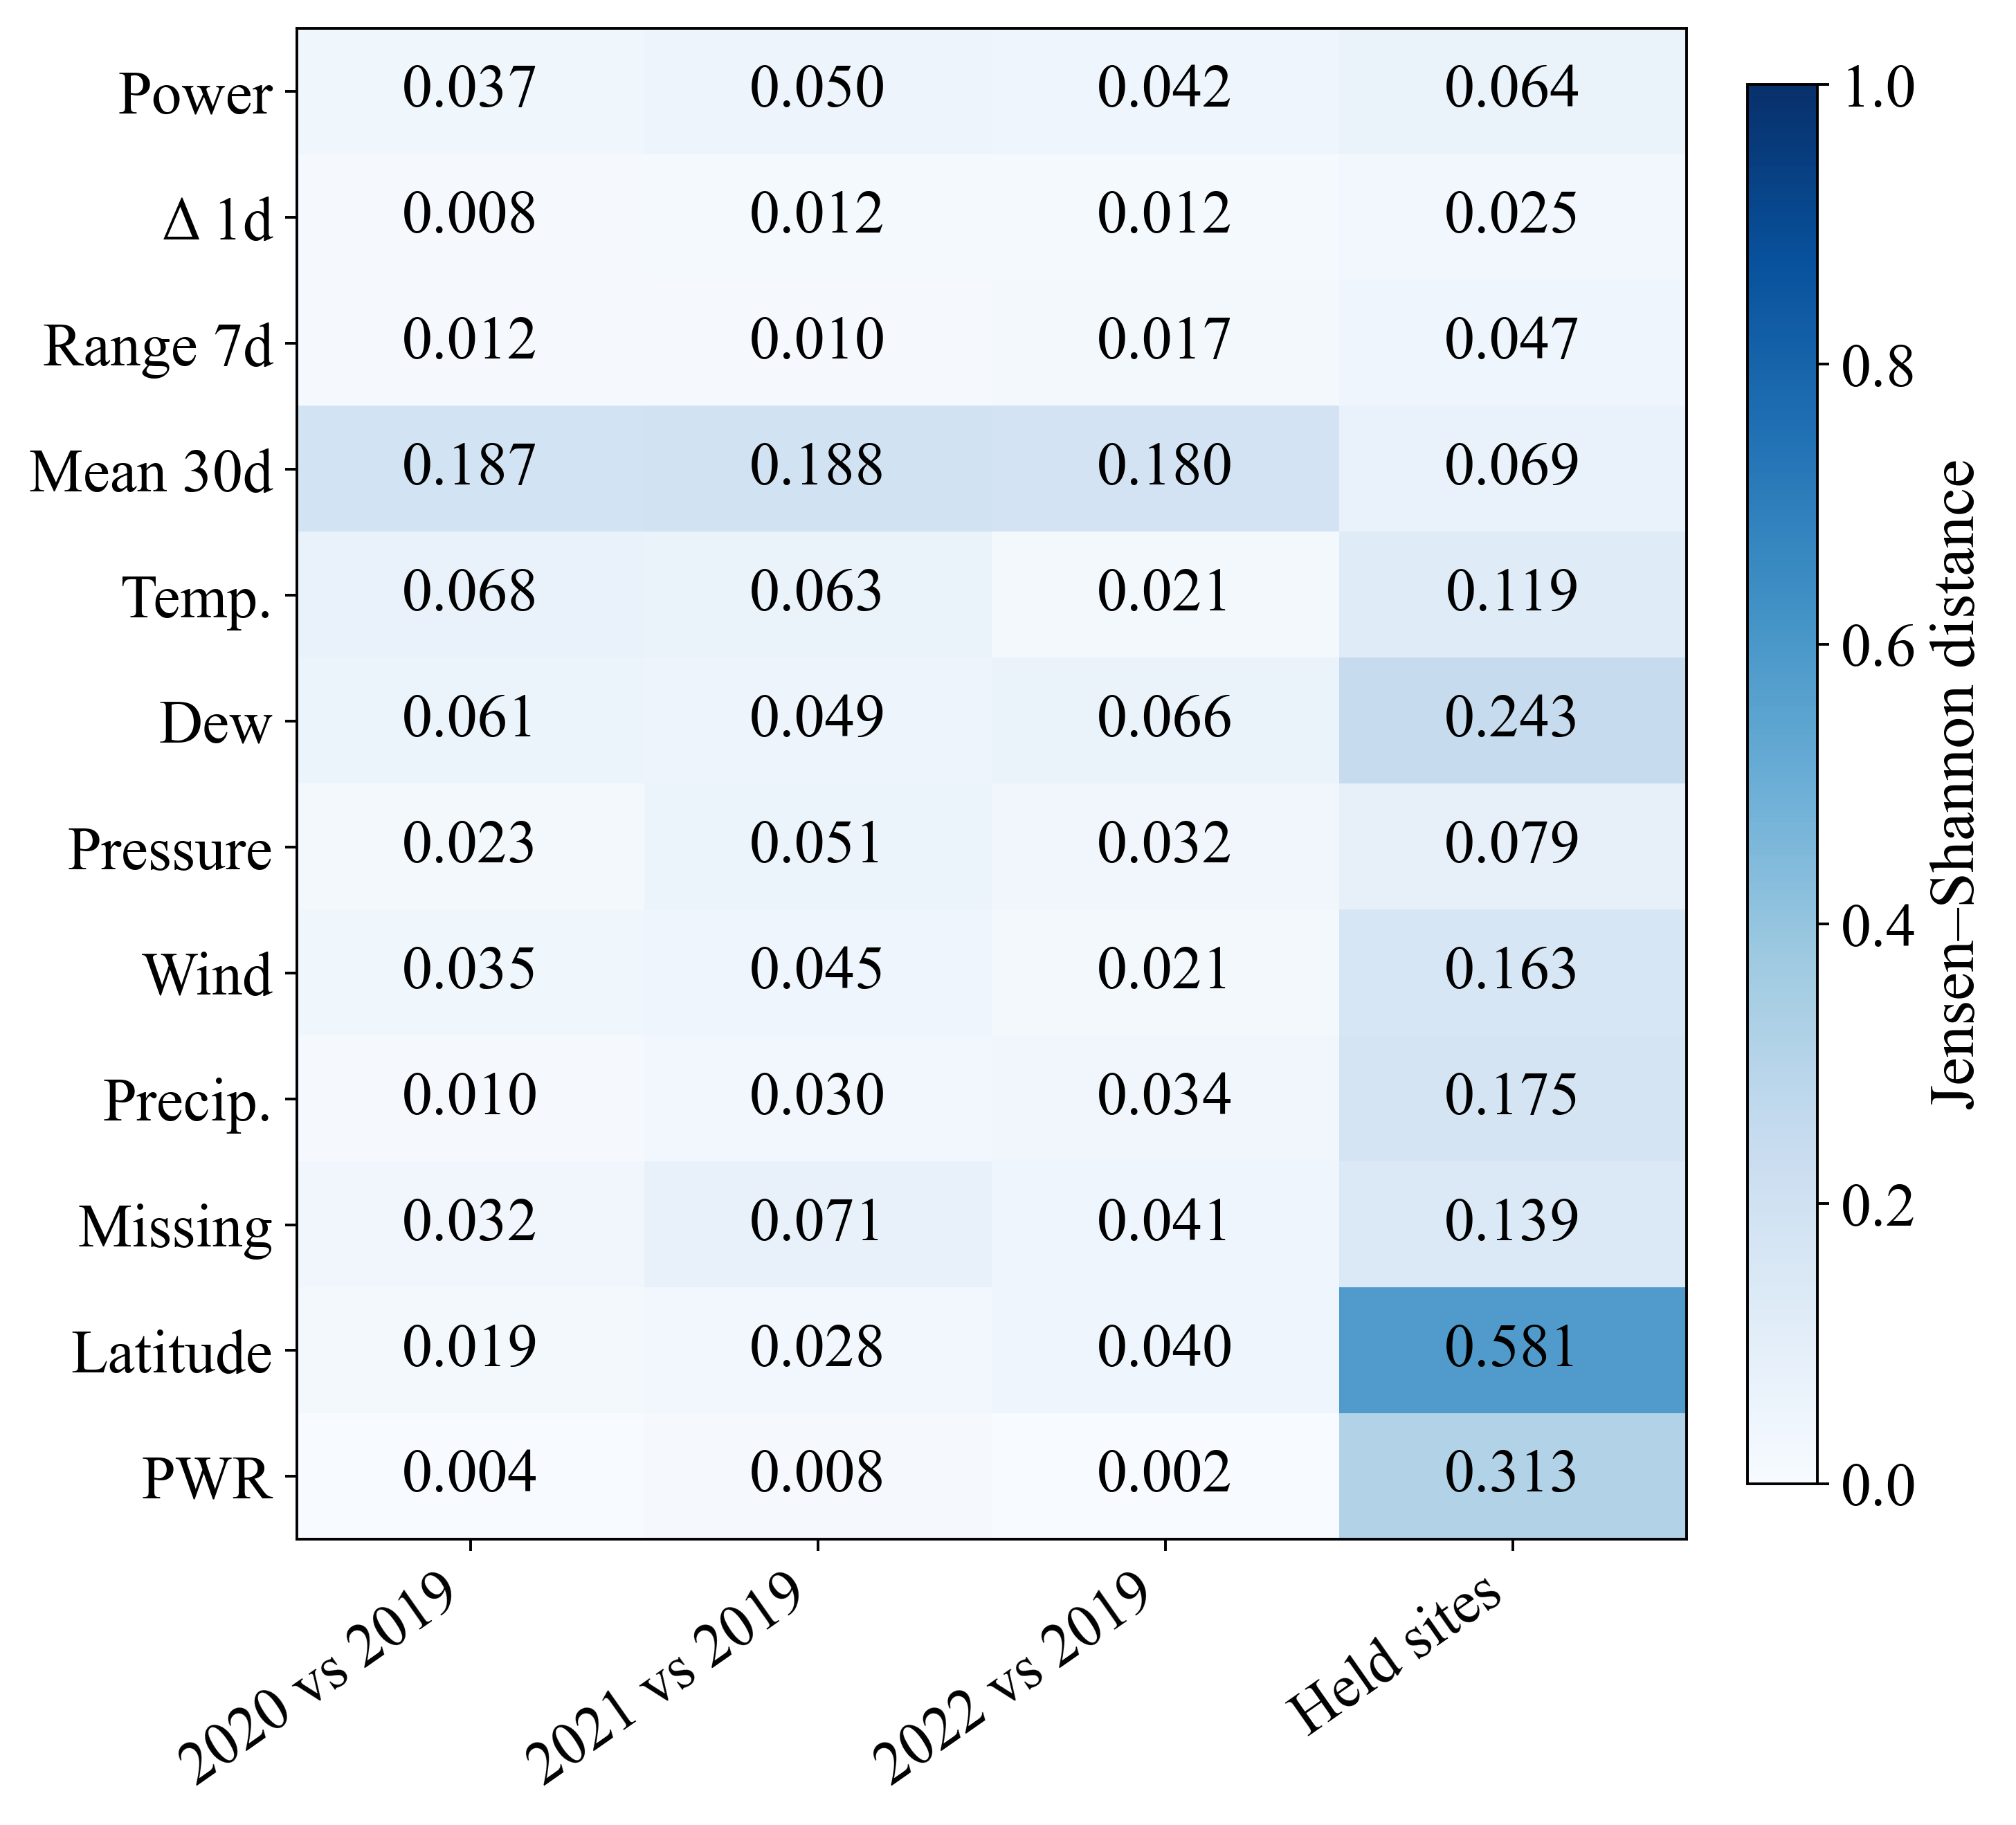

Input-distribution shifts. Annual and site comparisons use different reference cohorts; all observations are from the training period.

In [20]:
from scipy.spatial.distance import jensenshannon
drift_columns = ["power_pct","delta_1d","power_range_7d","power_mean_30d","temp_c","dewpoint_c",
    "pressure_hpa","wind_ms","precip_mm","weather_missing_fraction","plant_lat","reactor_is_pwr"]
drift_labels = ["Power","Δ 1d","Range 7d","Mean 30d","Temp.","Dew","Pressure","Wind","Precip.","Missing","Latitude","PWR"]


def reference_histograms(reference,comparison,name):
    finite = reference.dropna()
    if name == "power_pct" or name.startswith("power_mean"):
        edges = np.array([-np.inf,0,10,50,90,95,99,100,np.inf])
    elif name.startswith("delta"):
        edges = np.array([-np.inf,-50,-20,-5,-2,0,2,5,20,50,np.inf])
    elif name.startswith("power_range"):
        edges = np.array([-np.inf,0,2,10,20,50,90,100,np.inf])
    elif finite.nunique() <= 32:
        categories = sorted(set(finite))
        def category_probabilities(values):
            counts = np.array([(values==v).sum() for v in categories]+[
                (values.notna()&~values.isin(categories)).sum(),values.isna().sum()],float)
            return counts/counts.sum()
        return category_probabilities(reference),category_probabilities(comparison)
    else:
        cuts = np.unique(finite.quantile(np.linspace(0,1,11)).to_numpy())[:-1]
        edges = np.r_[-np.inf,cuts,np.inf]
    def probabilities(values):
        counts = np.histogram(values.dropna(),bins=edges)[0]
        counts = np.r_[counts,values.isna().sum()].astype(float)
        return counts/counts.sum()
    return probabilities(reference),probabilities(comparison)


drift_matrix = pd.DataFrame(index=drift_columns,columns=["2020 vs 2019","2021 vs 2019","2022 vs 2019","Held sites"],dtype=float)
for column in drift_columns:
    reference = analysis.loc[analysis.date.dt.year.eq(2019),column]
    for year in [2020,2021,2022]:
        first,second = reference_histograms(reference,analysis.loc[analysis.date.dt.year.eq(year),column],column)
        drift_matrix.loc[column,f"{year} vs 2019"] = jensenshannon(first,second,base=2)
    first,second = reference_histograms(analysis.loc[~analysis.plant_id.isin(heldout_sites),column],
        analysis.loc[analysis.plant_id.isin(heldout_sites),column],column)
    drift_matrix.loc[column,"Held sites"] = jensenshannon(first,second,base=2)
assert np.isfinite(drift_matrix).all().all()
fig,ax = plt.subplots(figsize=(8.1,8.1))
image = ax.imshow(drift_matrix,aspect="auto",vmin=0,vmax=1,cmap=MATRIX_PALETTES["shift"])
ax.set_xticks(range(4),drift_matrix.columns,rotation=35,ha="right")
ax.set_yticks(range(len(drift_labels)),drift_labels)
for row in range(len(drift_labels)):
    for column in range(4):
        value = drift_matrix.iloc[row,column]
        ax.text(column,row,matrix_number(value,3),ha="center",va="center",fontsize=18,
            color=annotation_color(image,value))
fig.colorbar(image,ax=ax,fraction=.046,pad=.04,label="Jensen–Shannon distance")
publication_figure(fig,"nb02_covariate_shift",drift_matrix.reset_index(names="Feature"),
    "Input-distribution shifts. Annual and site comparisons use different reference cohorts; all observations are from the training period.")


## Exact redundancy and preprocessing within folds

In [21]:
redundancy_rows = []
for window in [7, 14, 30]:
    difference = features[f"power_max_{window}d"] - features[f"power_min_{window}d"] - features[f"power_range_{window}d"]
    redundancy_rows.append({"Identity":f"max_{window}d − min_{window}d − range_{window}d", "Maximum absolute residual":difference.loc[observations.split.eq("train")].abs().max(), "Removed predictor":f"power_max_{window}d"})
scientific_table(pd.DataFrame(redundancy_rows), "nb02_exact_redundancy", "Algebraic redundancy assessed on training data only")
removed_features = [f"power_max_{window}d" for window in [7, 14, 30]]
model_features = features.drop(columns=removed_features).copy()
feature_names = model_features.columns.tolist()


def fit_preprocessor(training_indices: np.ndarray) -> Pipeline:
    """Return an independently fitted transform for exactly one training partition."""
    transform = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)), ("scaler", StandardScaler())])
    transform.fit(model_features.iloc[training_indices])
    return transform


example_train, example_eval = splits["forward_2021"]["train"], splits["forward_2021"]["evaluation"]
example_transform = fit_preprocessor(example_train)
example_train_scaled = example_transform.transform(model_features.iloc[example_train])
example_eval_scaled = example_transform.transform(model_features.iloc[example_eval])
assert np.isfinite(example_train_scaled).all() and np.isfinite(example_eval_scaled).all()
preprocessing_summary = pd.DataFrame({"Partition":["Forward 2021 training", "Forward 2021 evaluation"], "n":[len(example_train), len(example_eval)], "Predictors before imputation":[len(feature_names)]*2, "Predictors including indicators":[example_train_scaled.shape[1], example_eval_scaled.shape[1]], "Mean absolute standardized value":[np.abs(example_train_scaled).mean(), np.abs(example_eval_scaled).mean()]})
scientific_table(preprocessing_summary, "nb02_fold_preprocessing", "Transformation fit before 2021; evaluation differences may reflect distribution shift")
joblib.dump(example_transform, FEATURES_ROOT / "forward_2021_preprocessor.joblib");


**Algebraic redundancy assessed on training data only**

Identity,Maximum absolute residual,Removed predictor
max_7d − min_7d − range_7d,0.0000,power_max_7d
max_14d − min_14d − range_14d,0.0000,power_max_14d
max_30d − min_30d − range_30d,0.0000,power_max_30d


**Transformation fit before 2021; evaluation differences may reflect distribution shift**

Partition,n,Predictors before imputation,Predictors including indicators,Mean absolute standardized value
Forward 2021 training,57744,51,65,0.5647
Forward 2021 evaluation,19351,51,65,0.5967


In [22]:
vif_input = SimpleImputer(strategy="median").fit_transform(analysis[representatives])
vif_input = StandardScaler().fit_transform(vif_input)
vif_rows = []
for column, name in enumerate(representatives):
    target_values = vif_input[:,column]
    design = np.column_stack([np.ones(len(vif_input)), np.delete(vif_input, column, axis=1)])
    fitted = design @ np.linalg.lstsq(design, target_values, rcond=None)[0]
    residual_fraction = np.sum((target_values-fitted)**2)/np.sum((target_values-target_values.mean())**2)
    vif_rows.append({"Feature":name, "VIF (representative subset)":1/residual_fraction if residual_fraction>1e-12 else np.inf})
scientific_table(pd.DataFrame(vif_rows), "nb02_vif", "Multicollinearity among selected representatives; VIF is not an automatic feature-selection rule for trees")


**Multicollinearity among selected representatives; VIF is not an automatic feature-selection rule for trees**

Feature,VIF (representative subset)
power_pct,658.5239
delta_1d,4.3902
power_mean_7d,648.0834
power_std_7d,5.2966
power_mean_30d,3.5632
temp_c,1.1476
pressure_hpa,1.1472
wind_ms,1.1037
weather_missing_fraction,1.0038


## Uncertainty in weather associations

In [23]:
rng = np.random.default_rng(42)
correlation_intervals = []
for weather in weather_names:
    paired = adjusted[["power_pct", weather]].dropna().copy()
    paired["plant_id"] = site_days.loc[paired.index, "plant_id"]
    paired["one"] = 1
    paired["xx"] = paired.power_pct**2
    paired["yy"] = paired[weather]**2
    paired["xy"] = paired.power_pct*paired[weather]
    sums = paired.groupby("plant_id")[["one", "power_pct", weather, "xx", "yy", "xy"]].sum().to_numpy()
    resampled = sums[rng.integers(0, len(sums), size=(2000, len(sums)))].sum(axis=1)
    n, sx, sy, sxx, syy, sxy = resampled.T
    bootstrap_r = (sxy-sx*sy/n)/np.sqrt((sxx-sx*sx/n)*(syy-sy*sy/n))
    low, high = np.quantile(bootstrap_r, [.025, .975])
    correlation_intervals.append({"Weather":weather, "Sites":len(sums), "Adjusted Pearson r":paired[["power_pct", weather]].corr().iloc[0,1], "95% lower":low, "95% upper":high})
scientific_table(pd.DataFrame(correlation_intervals), "nb02_weather_cluster_intervals", "Clustered 95% intervals for weather associations; 2,000 site resamples")


**Clustered 95% intervals for weather associations; 2,000 site resamples**

Weather,Sites,Adjusted Pearson r,95% lower,95% upper
temp_c,57,0.0012,−0.0126,0.0139
dewpoint_c,54,0.0088,−0.0070,0.0224
pressure_hpa,42,0.0051,−0.0087,0.0185
wind_ms,57,−0.0007,−0.0092,0.0088
precip_mm,47,0.0015,−0.0066,0.0090


## Common temporal tensors

In [24]:
sequence_channels = ["power_pct", "power_change", *weather_names]
sequence_values = observations[sequence_channels].to_numpy(dtype=np.float32)
sequences = np.full((len(observations), len(sequence_channels), 30), np.nan, dtype=np.float32)
for segment, indices in observations.groupby(["reactor_id", "segment_index"], sort=False).groups.items():
    indices = np.asarray(indices)
    if len(indices) >= 30:
        windows = np.lib.stride_tricks.sliding_window_view(sequence_values[indices], window_shape=30, axis=0)
        sequences[indices[29:]] = windows
model_indices = np.flatnonzero(metadata.model_eligible)
assert np.allclose(sequences[model_indices,0,-1], model_features.iloc[model_indices].power_pct.to_numpy(), equal_nan=True)
assert np.isfinite(sequences[model_indices,0]).all()
window_records = []
for name in ["development", "site_transfer"]:
    for role, indices in splits[name].items():
        for window in [7, 14, 30]:
            window_records.append({"Split":name, "Role":role, "Window days":window, "n":len(indices), "Channels":len(sequence_channels), "Weather available fraction":np.isfinite(sequences[indices,2:,-window:]).mean()})
scientific_table(pd.DataFrame(window_records), "nb02_sequence_windows", "Comparable windows on shared observations; weather missingness is retained")
np.save(FEATURES_ROOT / "sequences_raw.npy", sequences)
model_features.to_parquet(FEATURES_ROOT / "features_raw.parquet", index=False)
metadata.to_parquet(FEATURES_ROOT / "observation_metadata.parquet", index=False)
feature_schema = {"feature_names":feature_names, "feature_groups":{k:[v for v in vals if v in feature_names] for k, vals in feature_groups.items()}, "sequence_channels":sequence_channels, "window_days":30, "removed_algebraic_features":removed_features, "preprocessing":"fit median imputation and standardization within each training fold", "run_id":RUN_ID, "test_labels_used_for_selection":False}
(FEATURES_ROOT / "feature_schema.json").write_text(json.dumps(feature_schema, ensure_ascii=False, indent=2));


**Comparable windows on shared observations; weather missingness is retained**

Split,Role,Window days,n,Channels,Weather available fraction
development,train,7,116904,7,0.8592
development,train,14,116904,7,0.8592
development,train,30,116904,7,0.8590
development,evaluation,7,20333,7,0.8442
development,evaluation,14,20333,7,0.8441
development,evaluation,30,20333,7,0.8450
site_transfer,train,7,80198,7,0.8422
site_transfer,train,14,80198,7,0.8422
site_transfer,train,30,80198,7,0.8421
site_transfer,evaluation,7,5634,7,0.9081


## Final representation

In [25]:
dictionary_rows = []
for group, names in feature_schema["feature_groups"].items():
    for name in names:
        unit = "dimensionless"
        if name.endswith("missing") or name == "reactor_is_pwr":
            unit = "0 / 1"
        elif "age_days" in name or name in ["zero_run_days", "days_since_change"]:
            unit = "days"
        elif name.startswith(("delta", "power_std", "power_range")):
            unit = "percentage points"
        elif name.startswith("power") and "fraction" not in name:
            unit = "% reported power"
        elif name.startswith(("temp_c", "dewpoint_c")):
            unit = "degrees C"
        elif name.startswith("pressure_hpa"):
            unit = "hPa"
        elif name.startswith("wind_ms"):
            unit = "m / s"
        elif name.startswith("precip_mm"):
            unit = "mm"
        elif name == "station_distance_km":
            unit = "km"
        elif name == "site_nameplate_mw":
            unit = "MW, site total"
        elif name == "site_generation_age_years":
            unit = "years since first site generator"
        elif name in ["plant_lat", "plant_lon"]:
            unit = "degrees"
        elif name == "site_nuclear_generators":
            unit = "count"
        dictionary_rows.append({"Group":group, "Feature":name, "Unit":unit})
feature_dictionary = pd.DataFrame(dictionary_rows)
for group_number, (group, part) in enumerate(feature_dictionary.groupby("Group", sort=False), 1):
    for block_number, start in enumerate(range(0, len(part), 8), 1):
        scientific_table(part.iloc[start:start+8].drop(columns="Group"), f"nb02_feature_dictionary_{group_number}_{block_number}", f"{group}")
feature_dictionary.to_csv(FEATURES_ROOT / "feature_dictionary.csv", index=False)


**Power level and temporal dynamics**

Feature,Unit
power_pct,% reported power
delta_1d,percentage points
delta_2d,percentage points
delta_3d,percentage points
delta_7d,percentage points
delta_14d,percentage points
power_mean_7d,% reported power
power_std_7d,percentage points


**Power level and temporal dynamics**

Feature,Unit
power_min_7d,% reported power
power_range_7d,percentage points
power_mean_14d,% reported power
power_std_14d,percentage points
power_min_14d,% reported power
power_range_14d,percentage points
power_mean_30d,% reported power
power_std_30d,percentage points


**Power level and temporal dynamics**

Feature,Unit
power_min_30d,% reported power
power_range_30d,percentage points
zero_run_days,days
days_since_change,days
power_window_fraction,dimensionless


... (4 outputs left out)

**Weather and observation quality**

Feature,Unit
precip_mm,mm
precip_mm_missing,0 / 1
precip_mm_mean7d,mm
precip_mm_age_days,days
weather_missing_fraction,dimensionless
station_distance_km,km


**Physical and calendar context**

Feature,Unit
reactor_is_pwr,0 / 1
site_nameplate_mw,"MW, site total"
site_nuclear_generators,count
site_generation_age_years,years since first site generator
plant_lat,degrees
plant_lon,degrees
dayofyear_sin,dimensionless
dayofyear_cos,dimensionless


## Connection to baselines, modern competitors and RACF-Net

In [26]:
design_trace = pd.DataFrame([
    {"ID":"D1","Evidence":"Shared information in power, rolling means, range and SD",
     "Candidate mechanism":"Shared representations, message agreement and regularization",
     "Required check":"NB03–04: errors of strong comparators; NB05: capacity-matched fusion and ablation"},
    {"ID":"D2","Evidence":"Unequal annual stability of one-day and three-day changes",
     "Candidate mechanism":"Short changes with 7/14/30-day context",
     "Required check":"One cohort for all windows; remove each scale separately"},
    {"ID":"D3","Evidence":"SCRAM on the first zero day and during continued zero power",
     "Candidate mechanism":"Agent regime state: respond, retain or abstain",
     "Required check":"Causal-state versus stateless; separate recall for flat and transition events"},
    {"ID":"D4","Evidence":"Weak adjusted weather associations; related missingness",
     "Candidate mechanism":"Reliability gate, age and masks, with a power fallback",
     "Required check":"No weather; block missingness; delay and noise; assess AP and calibration"},
    {"ID":"D5","Evidence":"Shifts in weather, reactor type and site context",
     "Candidate mechanism":"State updates from the available past only",
     "Required check":"New sites; frozen/adaptive comparison; no future labels in updates"},
    {"ID":"D6","Evidence":"MI changes when stable controls are replaced by documented controls",
     "Candidate mechanism":"Independent final expert with its own context",
     "Required check":"Shared cohort and hard controls; errors of each expert and the full model"},
    {"ID":"D7","Evidence":"Rare independent events and weak long-term linear memory",
     "Candidate mechanism":"Compact agents with explicit states, actions and utility",
     "Required check":"Message/action logs; interaction ablation; benefit relative to resource use"}
])
for block,offset in enumerate(range(0,len(design_trace),3),start=1):
    scientific_table(design_trace.iloc[offset:offset+3],f"nb02_design_trace_{block}",
                     "Evidence → mechanism → experimental test")
design_trace.to_csv(OUTPUT_ROOT / "Configs/nb02_model_design_trace.csv",index=False)


**Evidence → mechanism → experimental test**

ID,Evidence,Candidate mechanism,Required check
D1,"Shared information in power, rolling means, range and SD","Shared representations, message agreement and regularization",NB03–04: errors of strong comparators; NB05: capacity-matched fusion and ablation
D2,Unequal annual stability of one-day and three-day changes,Short changes with 7/14/30-day context,One cohort for all windows; remove each scale separately
D3,SCRAM on the first zero day and during continued zero power,"Agent regime state: respond, retain or abstain",Causal-state versus stateless; separate recall for flat and transition events


**Evidence → mechanism → experimental test**

ID,Evidence,Candidate mechanism,Required check
D4,Weak adjusted weather associations; related missingness,"Reliability gate, age and masks, with a power fallback",No weather; block missingness; delay and noise; assess AP and calibration
D5,"Shifts in weather, reactor type and site context",State updates from the available past only,New sites; frozen/adaptive comparison; no future labels in updates
D6,MI changes when stable controls are replaced by documented controls,Independent final expert with its own context,Shared cohort and hard controls; errors of each expert and the full model


**Evidence → mechanism → experimental test**

ID,Evidence,Candidate mechanism,Required check
D7,Rare independent events and weak long-term linear memory,"Compact agents with explicit states, actions and utility",Message/action logs; interaction ablation; benefit relative to resource use
